# 03 — Data Modelling

## 1. Purpose

This notebook fits and compares four unsupervised clustering approaches to identify patterns in workplace mental-health climate among 1,131 eligible technology-sector respondents.

The modelling scope is fixed by Notebook 01 and implemented by Notebook 02:
- Population: 1,131 eligible respondents.
- Clustering variables: 15 workplace-climate features.
- Feature domains: employer support, psychological safety, and disclosure/career climate.
- Missing values: none in the selected clustering features; no imputation is required.
- Excluded variables: demographics, personal diagnosis and treatment history, location, company size, age, and other contextual variables.

### 1.1 Models

|Model|	Representation|	Purpose|
|:--|:--|:--|
|K-Modes|Original categorical responses|Categorical centroid-based clustering|
|MCA + K-Means|	MCA coordinates derived from the indicator matrix|Centroid-based clustering in reduced categorical space|
|Agglomerative Hierarchical|Domain-balanced Gower dissimilarity|Hierarchical clustering using mixed nominal/ordinal dissimilarities|
|HDBSCAN|Domain-balanced Gower dissimilarity|Density-based clustering with explicit noise detection|

### 1.2 Modelling Principles

1. Do not assume that the same number of clusters is appropriate for every algorithm.
2. Evaluate a range of cluster counts or density parameters.
3. Use multiple random initialisations where the algorithm is stochastic.
4. Assess cluster quality using more than one diagnostic.
5. Use the prepared Gower dissimilarity matrix as a common external evaluation representation when calculating silhouette scores for the different model outputs.
6. Do not compare K-Modes cost, K-Means inertia, silhouette, DBCV, and cophenetic correlation as if they were interchangeable measures.
7. Do not automatically select the model with the highest numerical score. Consider stability, cluster size, noise, interpretability and methodological suitability.
The objective is to identify defensible workplace-climate profiles, not to predict an individual's mental-health diagnosis.

## 2. Environment and Imports

In [15]:
from pathlib import Path
import json
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import (
    linkage,
    cophenet,
    fcluster,
    dendrogram,
)
from scipy.spatial.distance import squareform

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

from kmodes.kmodes import KModes
import hdbscan

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)

ROOT = (
    Path.cwd().resolve().parent
    if Path.cwd().resolve().name == "notebooks"
    else Path.cwd().resolve()
)

PROCESSED_DIR = ROOT / "data" / "processed"

FIGURES_DIR = (
    ROOT
    / "reports"
    / "figures"
    / "data_modelling"
)

RESULTS_DIR = (
    ROOT
    / "reports"
    / "results"
    / "data_modelling"
)

for directory in [
    FIGURES_DIR,
    RESULTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Processed data:", PROCESSED_DIR)
print("Figures:", FIGURES_DIR)
print("Results:", RESULTS_DIR)

Project root: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering
Processed data: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\data\processed
Figures: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\reports\figures\data_modelling
Results: C:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\reports\results\data_modelling


### 2.1 Required Packages

The modelling notebook requires the following additional packages:
- `kmodes` — K-Modes clustering.
- `hdbscan` — HDBSCAN clustering.
- `scikit-learn` — K-Means, agglomerative clustering and evaluation metrics.
- `scipy` — hierarchical linkage and cophenetic correlation.
The notebook deliberately does not fit a second data-cleaning pipeline. It consumes the validated modelling inputs exported by Notebook 02.

## 3. Load and Validate Notebook 02 Outputs

In [2]:
INPUT_FILES = {
    "kmodes": (
        PROCESSED_DIR
        / "osmi_2016_kmodes_input.csv"
    ),

    "mca_indicator": (
        PROCESSED_DIR
        / "osmi_2016_mca_indicator_matrix.csv"
    ),

    "gower_typed": (
        PROCESSED_DIR
        / "osmi_2016_gower_typed_input.csv"
    ),

    "gower_dissimilarity": (
        PROCESSED_DIR
        / "osmi_2016_gower_dissimilarity.npy"
    ),

    "row_mapping": (
        PROCESSED_DIR
        / "osmi_2016_model_row_mapping.csv"
    ),

    "primary_cohort": (
        PROCESSED_DIR
        / "osmi_2016_primary_cohort.csv"
    ),

    "feature_metadata": (
        PROCESSED_DIR
        / "osmi_2016_feature_metadata.csv"
    ),

    "preparation_metadata": (
        PROCESSED_DIR
        / "osmi_2016_preparation_metadata.json"
    ),
}

missing_files = [
    str(path)
    for path in INPUT_FILES.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following Notebook 02 outputs are missing:\n"
        + "\n".join(missing_files)
        + "\n\nRun Notebook 02 before Notebook 03."
    )

X_kmodes = pd.read_csv(
    INPUT_FILES["kmodes"],
    dtype="string",
)

X_mca_indicator = pd.read_csv(
    INPUT_FILES["mca_indicator"],
)

X_gower_typed = pd.read_csv(
    INPUT_FILES["gower_typed"],
    dtype="string",
)

D_gower = np.load(
    INPUT_FILES["gower_dissimilarity"],
    allow_pickle=False,
)

model_row_mapping = pd.read_csv(
    INPUT_FILES["row_mapping"],
)

primary_cohort = pd.read_csv(
    INPUT_FILES["primary_cohort"],
)

feature_metadata = pd.read_csv(
    INPUT_FILES["feature_metadata"],
)

with open(
    INPUT_FILES["preparation_metadata"],
    "r",
    encoding="utf-8",
) as file:
    preparation_metadata = json.load(file)

print("Notebook 02 modelling inputs loaded.")

Notebook 02 modelling inputs loaded.


In [3]:
EXPECTED_N = 1131
EXPECTED_P = 15

PRIMARY_FEATURES = preparation_metadata["primary_features"]

FEATURES_BY_DOMAIN = preparation_metadata["feature_domains"]

assert len(PRIMARY_FEATURES) == EXPECTED_P
assert len(set(PRIMARY_FEATURES)) == EXPECTED_P

assert X_kmodes.shape == (EXPECTED_N, EXPECTED_P)
assert X_gower_typed.shape == (EXPECTED_N, EXPECTED_P)

assert X_mca_indicator.shape[0] == EXPECTED_N
assert D_gower.shape == (EXPECTED_N, EXPECTED_N)

assert len(model_row_mapping) == EXPECTED_N
assert len(primary_cohort) == EXPECTED_N

assert list(X_kmodes.columns) == PRIMARY_FEATURES
assert list(X_gower_typed.columns) == PRIMARY_FEATURES

assert not X_kmodes.isna().any().any()
assert not X_gower_typed.isna().any().any()
assert not X_mca_indicator.isna().any().any()

assert set(
    np.unique(X_mca_indicator.to_numpy())
).issubset({0, 1})

assert np.isfinite(D_gower).all()
assert np.allclose(D_gower, D_gower.T, atol=1e-7)
assert np.allclose(np.diag(D_gower), 0, atol=1e-7)

assert D_gower.min() >= -1e-7
assert D_gower.max() <= 1 + 1e-7

assert (
    model_row_mapping["model_row_index"].to_numpy()
    == np.arange(EXPECTED_N)
).all()

assert (
    model_row_mapping["source_row_position"].to_numpy()
    == primary_cohort["source_row_position"].to_numpy()
).all()

print("All modelling input validation checks passed.")
print("Respondents:", EXPECTED_N)
print("Primary features:", EXPECTED_P)
print("MCA indicator columns:", X_mca_indicator.shape[1])
print("Gower matrix:", D_gower.shape)

All modelling input validation checks passed.
Respondents: 1131
Primary features: 15
MCA indicator columns: 52
Gower matrix: (1131, 1131)


### 3.1 Why Row Alignment is Important

The three clustering representations must refer to exactly the same respondents in exactly the same order.

For example, cluster label 17 from K-Modes must refer to the same respondent as row 17 in the Gower matrix.

Notebook 02 exports model_row_mapping for this purpose. It preserves the relationship between each model row and its original source-row position.

A failure in row alignment would make cross-model comparison, respondent profiling and cluster interpretation invalid. The assertions above therefore stop the notebook if the representations do not align.

## 4. Evaluation Framework
The four algorithms do not optimise the same objective.
- K-Modes minimises categorical mismatch cost.
- K-Means minimises squared Euclidean distances in MCA coordinate space.
- Agglomerative clustering constructs a hierarchy from pairwise Gower dissimilarities.
- HDBSCAN identifies dense regions and can leave observations unassigned as noise.

Consequently, their native objective values cannot be directly ranked against one another.

A common external evaluation is useful: calculate the silhouette coefficient using the prepared Gower dissimilarity matrix for the labels produced by each algorithm.

This does not change how a model is fitted. It evaluates the resulting partitions against the same workplace-climate dissimilarity representation.

The silhouette coefficient is:
$$
s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}
$$

where:
- $(a(i))$ is the average dissimilarity between observation \(i\) and other observations in its own cluster.
- $(b(i))$ is the smallest average dissimilarity between observation \(i\) and observations in another cluster.

The score ranges from -1 to 1. Higher values generally indicate better separation, but a high score alone does not establish that a clustering solution is substantively useful.

In [4]:
def calculate_gower_silhouette(
    distance_matrix,
    labels,
    exclude_noise=False,
):
    """
    Calculate silhouette using the precomputed Gower matrix.

    Noise label -1 is excluded when requested.
    """
    labels = np.asarray(labels)

    if exclude_noise:
        valid_mask = labels != -1
    else:
        valid_mask = np.ones(len(labels), dtype=bool)

    filtered_labels = labels[valid_mask]
    filtered_distances = distance_matrix[
        np.ix_(valid_mask, valid_mask)
    ]

    unique_labels = np.unique(filtered_labels)

    if len(unique_labels) < 2:
        return np.nan

    if len(unique_labels) >= len(filtered_labels):
        return np.nan

    return float(
        silhouette_score(
            filtered_distances,
            filtered_labels,
            metric="precomputed",
        )
    )


def cluster_size_summary(labels):
    """
    Return cluster sizes, excluding noise from the cluster table.
    """
    labels = np.asarray(labels)

    values = pd.Series(labels, name="cluster")

    return (
        values[values != -1]
        .value_counts()
        .sort_index()
        .rename_axis("cluster")
        .reset_index(name="respondents")
    )


def cluster_summary_statistics(labels):
    """
    Summarise assigned observations and cluster-size balance.
    """
    labels = np.asarray(labels)

    assigned = labels != -1
    assigned_labels = labels[assigned]

    counts = pd.Series(
        assigned_labels
    ).value_counts()

    if len(counts) == 0:
        return {
            "n_clusters": 0,
            "assigned": int(assigned.sum()),
            "noise": int((~assigned).sum()),
            "noise_share": 1.0,
            "smallest_cluster": 0,
            "largest_cluster": 0,
            "smallest_cluster_share": np.nan,
        }

    return {
        "n_clusters": int(len(counts)),
        "assigned": int(assigned.sum()),
        "noise": int((~assigned).sum()),
        "noise_share": float((~assigned).mean()),
        "smallest_cluster": int(counts.min()),
        "largest_cluster": int(counts.max()),
        "smallest_cluster_share": float(
            counts.min() / assigned.sum()
        ),
    }

## 5. Model 1 — K-Modes

### 5.1 Rationale
K-Modes is designed for categorical data. Unlike K-Means, it does not calculate arithmetic means or rely on Euclidean distances between numerical feature vectors.

It represents each cluster using a mode: the most frequent category for each feature within that cluster.

Its dissimilarity measure is based on categorical mismatches:
$$
d(x_i,m_j)=\sum_{l=1}^{p}\mathbb{1}(x_{il}\neq m_{jl})
$$

where:
- $(x_i)$ is respondent $(i)$.
- $(m_j)$ is the categorical mode vector for cluster $(j)$.
- $(p)$ is the number of features.
- $(\mathbb{1})$ equals 1 when the categories differ and 0 when they match.
The algorithm assigns respondents to the cluster with the smallest categorical mismatch cost and updates cluster modes.

K-Modes is appropriate for the original 15 categorical responses. It does not require one-hot encoding.

The number of clusters, $(k)$, is not known in advance. Candidate values from 2 to 10 will be investigated. Each candidate will be fitted repeatedly with different random seeds to assess sensitivity to initialisation.

In [5]:
K_VALUES = range(2, 11)

KM_MODES_RUNS = 10

kmodes_results = []
kmodes_labels = {}
kmodes_models = {}

for k in K_VALUES:

    run_labels = []
    run_costs = []
    run_models = []

    for run in range(KM_MODES_RUNS):

        seed = RANDOM_STATE + run

        model = KModes(
            n_clusters=k,
            init="Huang",
            n_init=5,
            max_iter=100,
            verbose=0,
            random_state=seed,
        )

        labels = model.fit_predict(
            X_kmodes.to_numpy(dtype=object)
        )

        run_labels.append(labels)
        run_costs.append(float(model.cost_))
        run_models.append(model)

    # Use the lowest-cost run as the representative solution.
    best_run = int(np.argmin(run_costs))

    best_labels = run_labels[best_run]

    # Pairwise adjusted Rand index between independent runs.
    stability_scores = [
        adjusted_rand_score(
            run_labels[i],
            run_labels[j],
        )
        for i, j in combinations(
            range(KM_MODES_RUNS),
            2,
        )
    ]

    common_silhouette = calculate_gower_silhouette(
        D_gower,
        best_labels,
    )

    size_stats = cluster_summary_statistics(
        best_labels
    )

    kmodes_labels[k] = best_labels
    kmodes_models[k] = run_models[best_run]

    kmodes_results.append({
        "k": k,
        "best_cost": run_costs[best_run],
        "mean_cost": np.mean(run_costs),
        "cost_std": np.std(run_costs, ddof=1),
        "mean_run_stability_ari": np.mean(stability_scores),
        "stability_ari_std": np.std(stability_scores, ddof=1),
        "gower_silhouette": common_silhouette,
        **size_stats,
    })

kmodes_results = pd.DataFrame(kmodes_results)

display(
    kmodes_results.sort_values(
        "k"
    ).round(4)
)

,k,best_cost,mean_cost,cost_std,mean_run_stability_ari,stability_ari_std,gower_silhouette,n_clusters,assigned,noise,noise_share,smallest_cluster,largest_cluster,smallest_cluster_share
0,2,6946.0,6954.9,11.3083,0.8012,0.2080,0.1842,2,1131,0,0.0,531,600,0.4695
1,3,6221.0,6274.8,42.2790,0.5925,0.1360,0.1492,3,1131,0,0.0,287,542,0.2538
2,4,5991.0,6048.9,37.9369,0.3812,0.0793,0.1202,4,1131,0,0.0,156,388,0.1379
3,5,5723.0,5840.4,64.2031,0.3051,0.0490,0.0988,5,1131,0,0.0,165,269,0.1459
4,6,5599.0,5668.4,43.0715,0.3007,0.0679,0.0815,6,1131,0,0.0,134,312,0.1185
5,7,5461.0,5541.4,51.5002,0.2452,0.0470,0.0829,7,1131,0,0.0,86,214,0.0760
6,8,5384.0,5434.1,37.8636,0.2360,0.0350,0.0753,8,1131,0,0.0,59,202,0.0522
7,9,5266.0,5326.2,36.0179,0.2295,0.0350,0.0640,9,1131,0,0.0,74,180,0.0654
8,10,5212.0,5287.6,38.5752,0.2087,0.0263,0.0632,10,1131,0,0.0,57,198,0.0504


### 5.2 Interpreting K-Modes Results

The K-Modes cost is the total number of categorical mismatches between respondents and their assigned cluster modes. A lower cost is expected as the number of clusters increases. It should therefore not be used alone to select $(k)$.

The more useful diagnostics are:
- **Cost:** the native optimisation objective.
- **Run stability:** whether repeated initialisations produce similar partitions.
- **Gower silhouette:** how well the resulting groups are separated under the common workplace-climate dissimilarity representation.
- **Cluster sizes:** whether the solution produces extremely small or disproportionately large groups.

The adjusted Rand index (ARI) measures similarity between two partitions while correcting for chance. It ranges approximately from -1 to 1, with 1 indicating identical partitions.

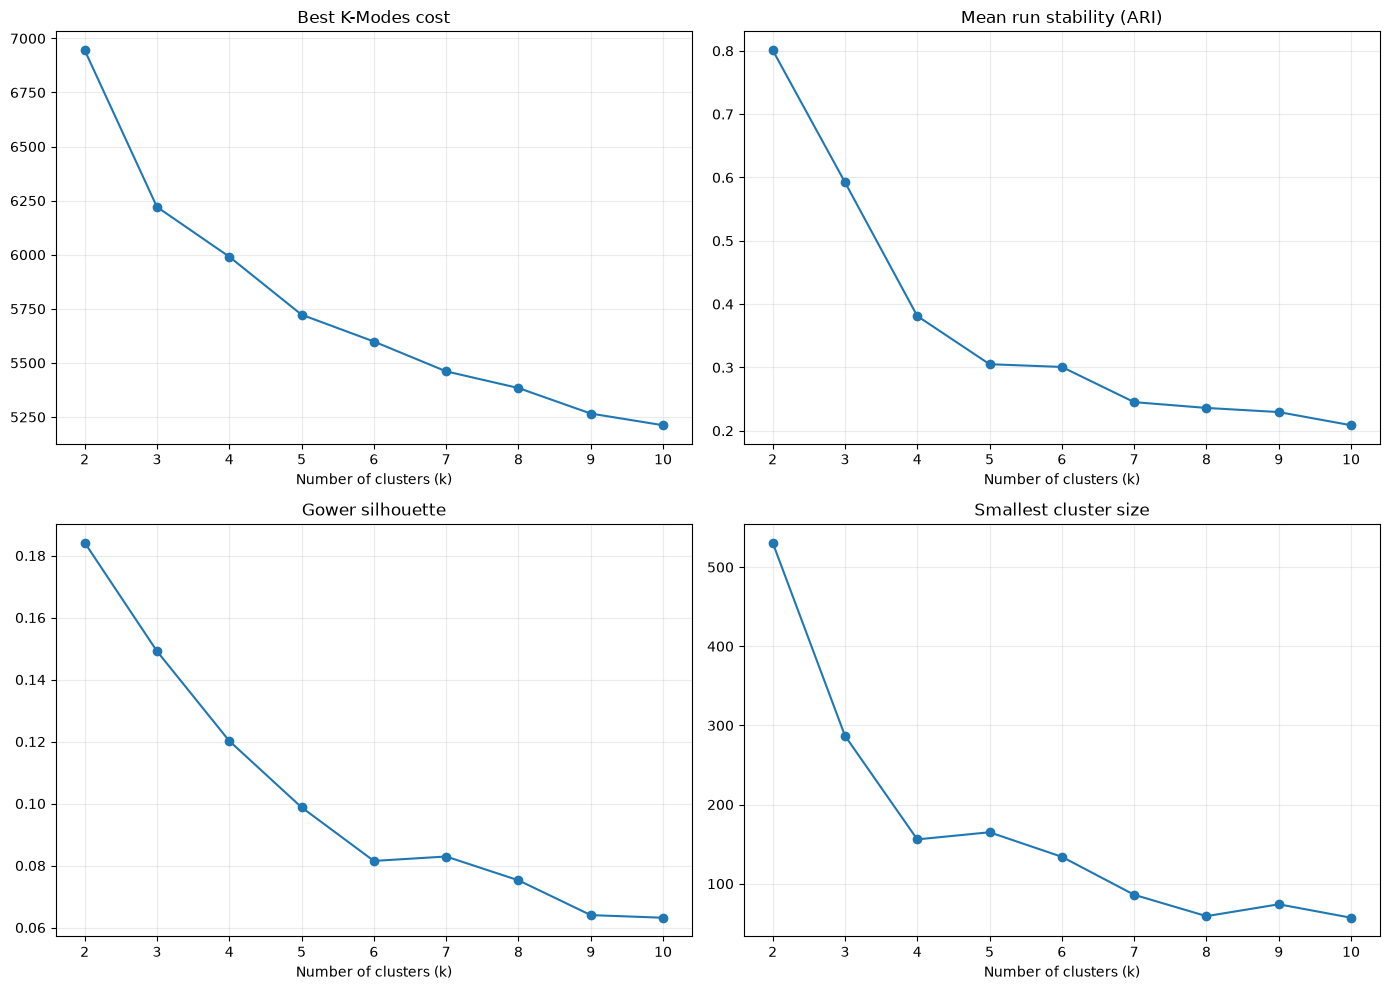

In [6]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

axes = axes.ravel()

plots = [
    ("best_cost", "Best K-Modes cost"),
    ("mean_run_stability_ari", "Mean run stability (ARI)"),
    ("gower_silhouette", "Gower silhouette"),
    ("smallest_cluster", "Smallest cluster size"),
]

for ax, (column, title) in zip(axes, plots):

    ax.plot(
        kmodes_results["k"],
        kmodes_results[column],
        marker="o",
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "kmodes_model_selection.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 6. Model 2 — Multiple Correspondence Analysis and K-Means

###6.1 Rationale

K-Means requires numerical coordinates and uses Euclidean distance. Applying it directly to nominal survey responses would impose an inappropriate numerical interpretation on category labels.

Multiple Correspondence Analysis (MCA) provides a suitable way to represent categorical response patterns in a lower-dimensional numerical space.

Notebook 02 exports a complete disjunctive, or one-hot indicator, matrix. MCA is fitted here, not in the preparation notebook.

MCA is a correspondence-analysis method applied to categorical data. It represents associations between categories as dimensions in a low-dimensional space.

The resulting respondent coordinates can then be used by K-Means.

### 6.2 MCA Calculation
For the indicator matrix $(Z)$, let:
$$
P=\frac{Z}{N}
$$

where $(N)$ is the number of respondents.

Let $(r)$ and $(c)$ represent the row and column masses of $(P)$. MCA decomposes the standardised residual matrix:
$$
S=D_r^{-1/2}(P-rc^T)D_c^{-1/2}
$$

where $(D_r)$ and $(D_c)$ are diagonal matrices of row and column masses.

Singular value decomposition gives:
$$
S=U\Sigma V^T
$$

The respondent principal coordinates are:
$$
F=D_r^{-1/2}U\Sigma
$$

The coordinates represent respondents in the MCA space. K-Means is then applied to these coordinates.

In [7]:
# MCA input: the indicator matrix produced by Notebook 02.
Z = X_mca_indicator.to_numpy(dtype=np.float64)

n, p = Z.shape

if not np.allclose(Z.sum(axis=1), len(PRIMARY_FEATURES)):
    raise AssertionError(
        "Each respondent should have exactly one active "
        "category per original feature."
    )

# Relative frequencies.
P = Z / Z.sum()

# Row and column masses.
row_masses = P.sum(axis=1)
column_masses = P.sum(axis=0)

if np.any(row_masses <= 0) or np.any(column_masses <= 0):
    raise ValueError(
        "MCA cannot proceed with zero-mass rows or columns."
    )

# Standardised residual matrix.
expected = np.outer(
    row_masses,
    column_masses,
)

S = (
    P - expected
) / np.sqrt(
    np.outer(
        row_masses,
        column_masses,
    )
)

# Singular value decomposition.
U, singular_values, VT = np.linalg.svd(
    S,
    full_matrices=False,
)

# MCA principal inertia.
eigenvalues = singular_values ** 2

# Remove numerically negligible dimensions.
tolerance = (
    np.finfo(float).eps
    * max(S.shape)
    * singular_values[0]
)

valid_dimensions = singular_values > tolerance

U = U[:, valid_dimensions]
singular_values = singular_values[valid_dimensions]
eigenvalues = eigenvalues[valid_dimensions]

# Respondent principal coordinates.
MCA_COORDINATES = (
    U * singular_values
) / np.sqrt(row_masses[:, None])

mca_variance = eigenvalues / eigenvalues.sum()

mca_summary = pd.DataFrame({
    "dimension": np.arange(1, len(eigenvalues) + 1),
    "eigenvalue": eigenvalues,
    "inertia_percentage": mca_variance * 100,
    "cumulative_inertia_percentage": (
        np.cumsum(mca_variance) * 100
    ),
})

display(mca_summary.head(20))

print("MCA coordinate shape:", MCA_COORDINATES.shape)
print(
    "Total inertia:",
    round(float(eigenvalues.sum()), 6),
)

,dimension,eigenvalue,inertia_percentage,cumulative_inertia_percentage
0,1,0.306666,12.432389,12.432389
1,2,0.153157,6.209063,18.641452
2,3,0.122313,4.958635,23.600087
3,4,0.103119,4.180497,27.780583
4,5,0.096852,3.926416,31.706999
5,6,0.091296,3.701188,35.408187
6,7,0.085913,3.482950,38.891138
7,8,0.084342,3.419278,42.310416
8,9,0.076793,3.113238,45.423653
9,10,0.075810,3.073371,48.497025


MCA coordinate shape: (1131, 37)
Total inertia: 2.466667


### 6.3 Selecting the MCA Dimensionality

Retaining every dimension would undermine the purpose of dimensionality reduction. Retaining too few dimensions could discard meaningful response-pattern information.

The notebook uses a cumulative inertia threshold of 80%, subject to a maximum of 20 dimensions. This is a practical modelling rule rather than a universal statistical law.

The selected dimensionality will be recorded so that the modelling decision is transparent and reproducible.

In [8]:
MCA_INERTIA_THRESHOLD = 0.80
MCA_MAX_COMPONENTS = 20

components_to_threshold = (
    np.searchsorted(
        np.cumsum(mca_variance),
        MCA_INERTIA_THRESHOLD,
    )
    + 1
)

N_MCA_COMPONENTS = min(
    components_to_threshold,
    MCA_MAX_COMPONENTS,
    MCA_COORDINATES.shape[1],
)

if N_MCA_COMPONENTS < 2:
    raise ValueError(
        "Insufficient non-zero MCA dimensions for clustering."
    )

X_mca = MCA_COORDINATES[:, :N_MCA_COMPONENTS]

print("Selected MCA dimensions:", N_MCA_COMPONENTS)
print(
    "Cumulative inertia retained:",
    f"{mca_variance[:N_MCA_COMPONENTS].sum() * 100:.2f}%",
)

print("MCA modelling matrix:", X_mca.shape)

Selected MCA dimensions: 20
Cumulative inertia retained: 73.99%
MCA modelling matrix: (1131, 20)


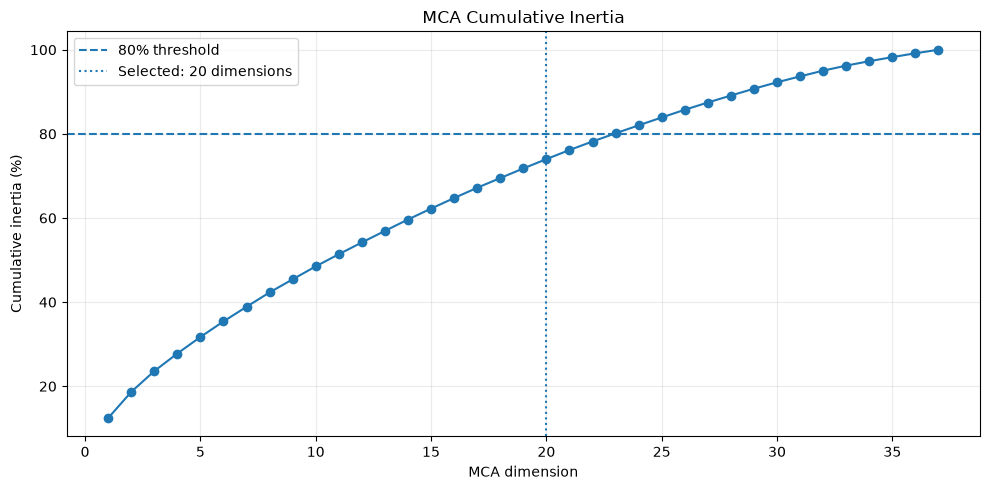

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    mca_summary["dimension"],
    mca_summary["cumulative_inertia_percentage"],
    marker="o",
)

ax.axhline(
    MCA_INERTIA_THRESHOLD * 100,
    linestyle="--",
    label="80% threshold",
)

ax.axvline(
    N_MCA_COMPONENTS,
    linestyle=":",
    label=f"Selected: {N_MCA_COMPONENTS} dimensions",
)

ax.set_title("MCA Cumulative Inertia")
ax.set_xlabel("MCA dimension")
ax.set_ylabel("Cumulative inertia (%)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mca_cumulative_inertia.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 6.4 K-Means Clustering in MCA Space

K-Means partitions numerical observations into $(k)$ clusters by minimising within-cluster squared Euclidean distances:
$$
J=\sum_{j=1}^{k}\sum_{x_i\in C_j}
\|x_i-\mu_j\|_2^2
$$

where $(\mu_j)$ is the centroid of cluster $(j)$.

K-Means is suitable here because MCA has transformed the categorical response patterns into numerical coordinates.

It would not be methodologically appropriate to apply ordinary K-Means directly to the original string-valued survey responses.

Candidate cluster counts from 2 to 10 are evaluated using repeated initialisations.

In [10]:
KMEANS_RUNS = 20

kmeans_results = []
kmeans_labels = {}
kmeans_models = {}

for k in K_VALUES:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=KMEANS_RUNS,
        max_iter=500,
        random_state=RANDOM_STATE,
    )

    labels = model.fit_predict(X_mca)

    silhouette_mca = silhouette_score(
        X_mca,
        labels,
        metric="euclidean",
    )

    db_index = davies_bouldin_score(
        X_mca,
        labels,
    )

    ch_index = calinski_harabasz_score(
        X_mca,
        labels,
    )

    silhouette_gower = calculate_gower_silhouette(
        D_gower,
        labels,
    )

    size_stats = cluster_summary_statistics(labels)

    kmeans_labels[k] = labels
    kmeans_models[k] = model

    kmeans_results.append({
        "k": k,
        "inertia": float(model.inertia_),
        "mca_silhouette": float(silhouette_mca),
        "davies_bouldin": float(db_index),
        "calinski_harabasz": float(ch_index),
        "gower_silhouette": silhouette_gower,
        **size_stats,
    })

kmeans_results = pd.DataFrame(kmeans_results)

display(
    kmeans_results.round(4)
)

,k,inertia,mca_silhouette,davies_bouldin,calinski_harabasz,gower_silhouette,n_clusters,assigned,noise,noise_share,smallest_cluster,largest_cluster,smallest_cluster_share
0,2,1817.7530,0.1157,2.6205,153.1318,0.2001,2,1131,0,0.0,496,635,0.4385
1,3,1692.4497,0.0920,2.6826,123.9184,0.1534,3,1131,0,0.0,286,491,0.2529
2,4,1604.8552,0.0975,2.4249,107.5483,0.1226,4,1131,0,0.0,52,471,0.0460
3,5,1543.9985,0.0796,2.6094,94.8614,0.0933,5,1131,0,0.0,51,350,0.0451
4,6,1478.9904,0.0925,2.3391,89.0442,0.0875,6,1131,0,0.0,28,365,0.0248
5,7,1429.6441,0.0887,2.3464,83.1626,0.0911,7,1131,0,0.0,50,309,0.0442
6,8,1386.1451,0.0865,2.3414,78.4882,0.0862,8,1131,0,0.0,28,291,0.0248
7,9,1345.2996,0.0926,2.2862,74.9575,0.0754,9,1131,0,0.0,28,249,0.0248
8,10,1308.7784,0.0932,2.2285,71.9028,0.0695,10,1131,0,0.0,28,240,0.0248


### 6.5 Interpreting K-Means Diagnostics

The MCA-space silhouette, Davies–Bouldin index and Calinski–Harabasz index assess separation and compactness in the space in which K-Means was fitted.
- Higher silhouette is generally preferable.
- Lower Davies–Bouldin is generally preferable.
- Higher Calinski–Harabasz is generally preferable.
- Lower inertia is expected as the number of clusters increases.

The Gower silhouette is an additional external diagnostic. It evaluates the K-Means partition against the same domain-balanced Gower dissimilarity used for the other methods.

These measures answer different questions. A model can perform well in MCA space without producing equally well-separated groups under Gower dissimilarity.

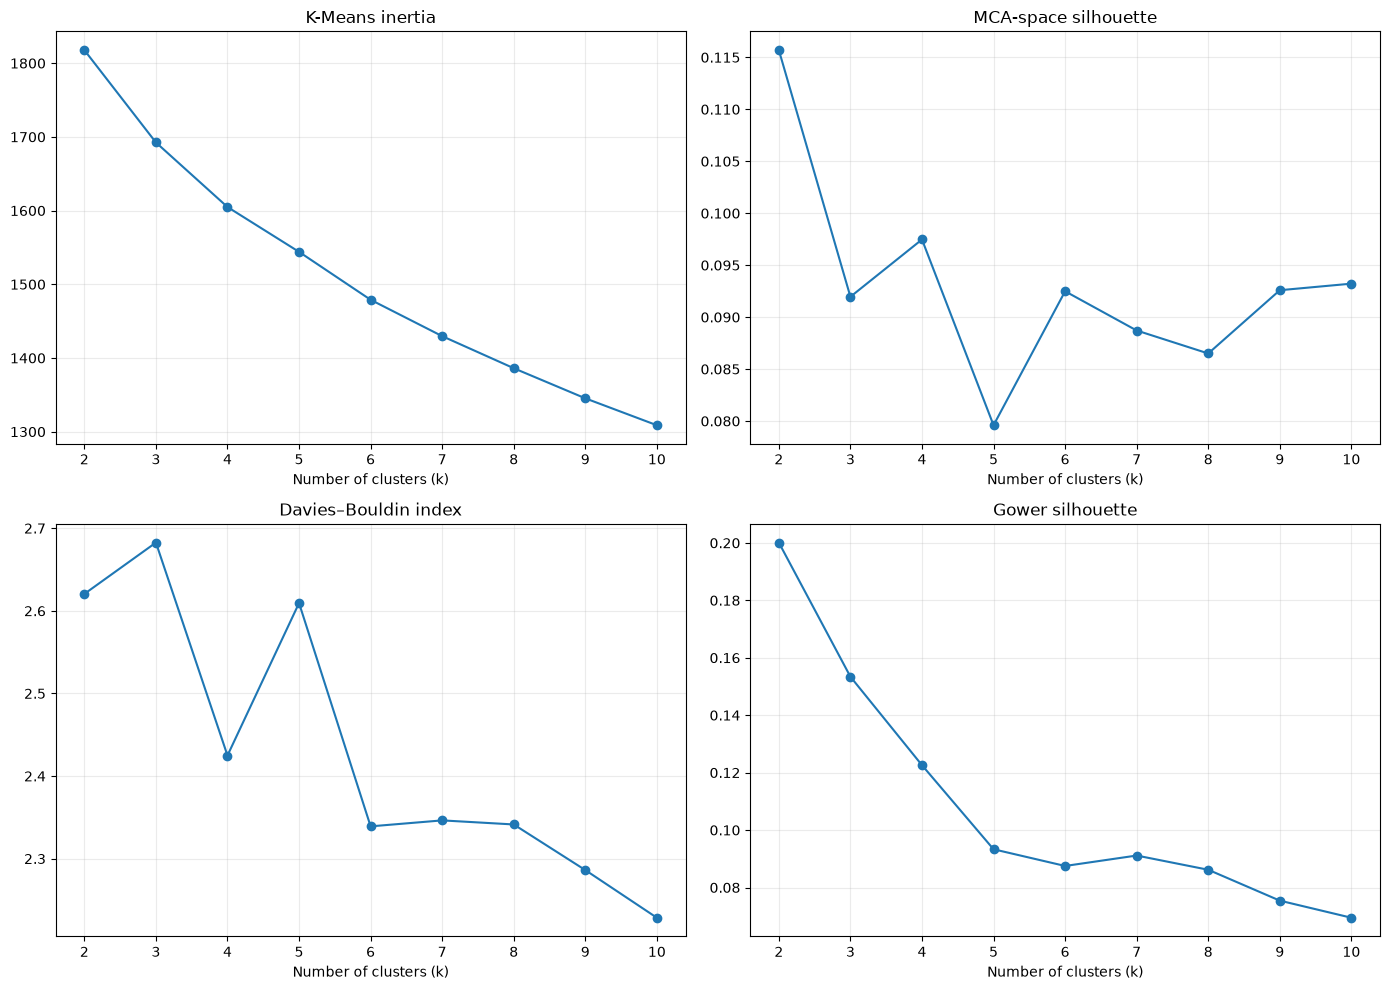

In [11]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

axes = axes.ravel()

plots = [
    ("inertia", "K-Means inertia"),
    ("mca_silhouette", "MCA-space silhouette"),
    ("davies_bouldin", "Davies–Bouldin index"),
    ("gower_silhouette", "Gower silhouette"),
]

for ax, (column, title) in zip(axes, plots):

    ax.plot(
        kmeans_results["k"],
        kmeans_results[column],
        marker="o",
    )

    ax.set_title(title)
    ax.set_xlabel("Number of clusters (k)")
    ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mca_kmeans_model_selection.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 7. Model 3 — Agglomerative Hierarchical Clustering with Gower Dissimilarity

### 7.1 Rationale

Agglomerative hierarchical clustering is a bottom-up clustering method. Initially, each respondent forms an individual cluster. The algorithm repeatedly merges the two closest clusters until the hierarchy is complete.

The method is appropriate for this project because the prepared Gower matrix represents pairwise dissimilarities between respondents while respecting nominal and ordinal measurement levels.

The selected linkage method is average linkage.

For clusters $(A)$ and $(B)$, average linkage is:
$$
D(A,B)=
\frac{1}{|A||B|}
\sum_{i\in A}\sum_{j\in B}d(i,j)
$$

It calculates the average pairwise dissimilarity between observations in two clusters.

Ward linkage is not used. Ward's method relies on increases in within-cluster sums of squares and is not appropriate for an arbitrary precomputed Gower dissimilarity matrix.

### 7.2 Fit the Hierarchical Model

In [12]:
# scipy linkage requires a condensed distance vector,
# rather than the square distance matrix.
D_condensed = squareform(
    D_gower,
    checks=True,
)

# Build the complete hierarchical tree once.
hierarchical_tree = linkage(
    D_condensed,
    method="average",
    optimal_ordering=False,
)

# Cophenetic correlation measures how faithfully the
# dendrogram represents the original pairwise dissimilarities.
cophenetic_correlation, cophenetic_distances = cophenet(
    hierarchical_tree,
    D_condensed,
)

print(
    "Cophenetic correlation:",
    round(float(cophenetic_correlation), 4),
)

Cophenetic correlation: 0.5162


### 7.3 Cophenetic Correlation

The cophenetic distance between two respondents is the dissimilarity level at which they first become members of the same cluster in the dendrogram.

The cophenetic correlation coefficient (CPCC) is the Pearson correlation between:
- The original pairwise Gower dissimilarities.
- The corresponding cophenetic distances derived from the hierarchy.
$$
r_c =
\operatorname{corr}(d_{ij},c_{ij})
$$

A higher value indicates that the dendrogram more faithfully preserves the original pairwise dissimilarity structure.

**Important:** CPCC evaluates the fidelity of the hierarchical representation. It is not a direct measure of the quality of a particular cut of the dendrogram. It must not be interpreted as a cluster-validity score.

In [13]:
hierarchical_results = []
hierarchical_labels = {}

for k in K_VALUES:

    labels = fcluster(
        hierarchical_tree,
        t=k,
        criterion="maxclust",
    )

    # Convert labels to zero-based values for consistency.
    labels = labels - 1

    silhouette_gower = calculate_gower_silhouette(
        D_gower,
        labels,
    )

    size_stats = cluster_summary_statistics(labels)

    hierarchical_labels[k] = labels

    hierarchical_results.append({
        "k": k,
        "gower_silhouette": silhouette_gower,
        "cophenetic_correlation": float(
            cophenetic_correlation
        ),
        **size_stats,
    })

hierarchical_results = pd.DataFrame(
    hierarchical_results
)

display(
    hierarchical_results.round(4)
)

,k,gower_silhouette,cophenetic_correlation,n_clusters,assigned,noise,noise_share,smallest_cluster,largest_cluster,smallest_cluster_share
0,2,0.1700,0.5162,2,1131,0,0.0,2,1129,0.0018
1,3,0.0857,0.5162,3,1131,0,0.0,2,1121,0.0018
2,4,0.1194,0.5162,4,1131,0,0.0,2,678,0.0018
3,5,0.0954,0.5162,5,1131,0,0.0,2,678,0.0018
4,6,0.0740,0.5162,6,1131,0,0.0,2,671,0.0018
5,7,0.0583,0.5162,7,1131,0,0.0,2,665,0.0018
6,8,0.0493,0.5162,8,1131,0,0.0,2,665,0.0018
7,9,0.0347,0.5162,9,1131,0,0.0,2,665,0.0018
8,10,0.0272,0.5162,10,1131,0,0.0,2,665,0.0018


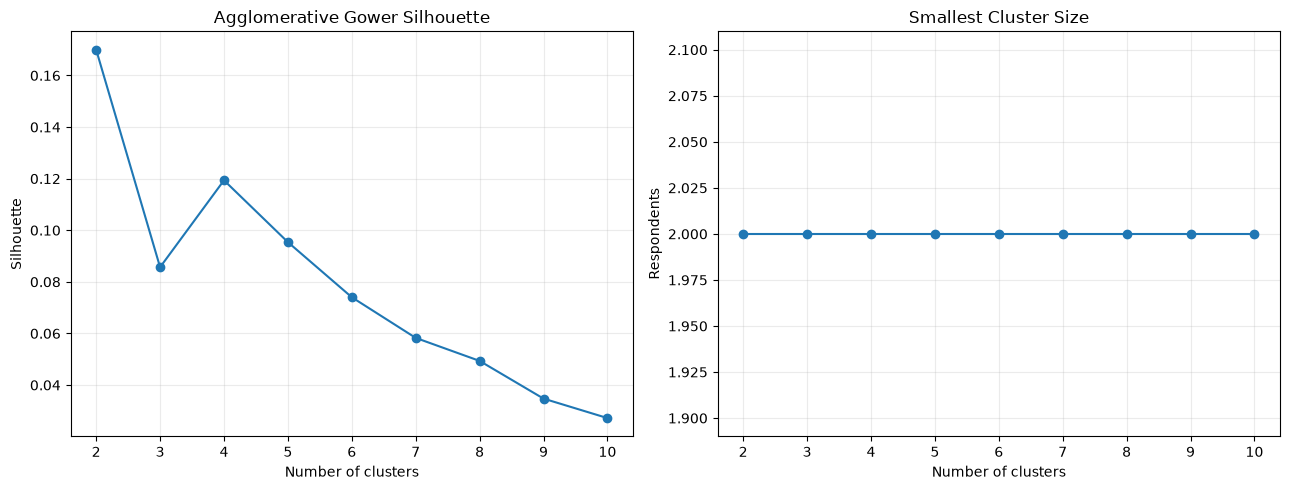

In [14]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

axes[0].plot(
    hierarchical_results["k"],
    hierarchical_results["gower_silhouette"],
    marker="o",
)

axes[0].set_title("Agglomerative Gower Silhouette")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette")
axes[0].grid(alpha=0.25)

axes[1].plot(
    hierarchical_results["k"],
    hierarchical_results["smallest_cluster"],
    marker="o",
)

axes[1].set_title("Smallest Cluster Size")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Respondents")
axes[1].grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hierarchical_model_selection.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 7.4 Visualise the Dendrogram
A dendrogram shows the order and dissimilarity levels at which clusters are merged. With 1,131 respondents, a fully labelled dendrogram would be difficult to interpret.

The plot below therefore omits individual respondent labels and displays a truncated hierarchy. It is an overview of the hierarchical structure, not a substitute for the quantitative model-selection results.

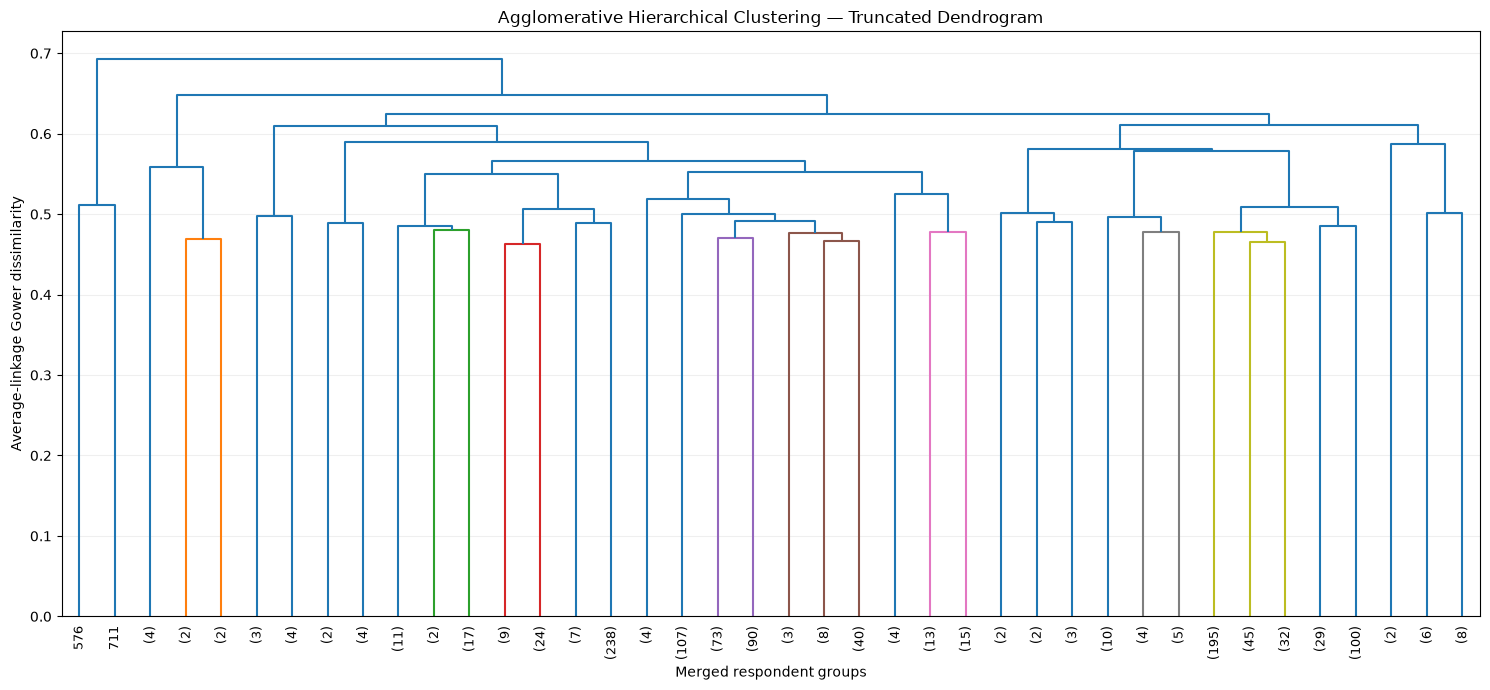

In [16]:
fig, ax = plt.subplots(figsize=(15, 7))

dendrogram(
    hierarchical_tree,
    truncate_mode="lastp",
    p=40,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    ax=ax,
)

ax.set_title(
    "Agglomerative Hierarchical Clustering — Truncated Dendrogram"
)

ax.set_xlabel("Merged respondent groups")
ax.set_ylabel("Average-linkage Gower dissimilarity")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hierarchical_dendrogram.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 8. Model 4 — HDBSCAN with Gower Dissimilarity

### 8.1 Rationale
HDBSCAN is a density-based clustering algorithm. Unlike K-Modes, K-Means and agglomerative clustering, it does not require the analyst to specify the number of clusters in advance.

It identifies dense regions of observations and can classify respondents that do not belong convincingly to any dense region as noise.

This is useful for investigating whether the workplace-climate data contain naturally dense respondent groups, rather than forcing every respondent into a cluster.

The model uses the domain-balanced Gower dissimilarity matrix prepared in Notebook 02.

### 8.2 Important HDBSCAN Parameters

|Parameter|	Meaning|
|:--|:--|
|`min_cluster_size`|Smallest group that can be considered a cluster|
|`min_samples`|Density requirement used to identify core observations|
|`cluster_selection_method`|Method used to extract clusters from the condensed tree|

`min_cluster_size` and `min_samples` are investigated over a limited, predeclared grid. This avoids choosing parameters solely because they produce a preferred number of clusters.

The model uses metric="precomputed" because the input is a pairwise Gower dissimilarity matrix, not a conventional numerical feature matrix.

In [18]:
HDBSCAN_MIN_CLUSTER_SIZES = [
    15,
    25,
    40,
    60,
]

HDBSCAN_MIN_SAMPLES = [
    5,
    10,
    15,
]

hdbscan_results = []
hdbscan_labels = {}
hdbscan_models = {}

D_gower = D_gower.astype(np.float64)

for min_cluster_size in HDBSCAN_MIN_CLUSTER_SIZES:

    for min_samples in HDBSCAN_MIN_SAMPLES:

        model = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_samples,
            metric="precomputed",
            cluster_selection_method="eom",
            prediction_data=False,
            approx_min_span_tree=False,
        )

        labels = model.fit_predict(D_gower)

        n_clusters = len(
            set(labels) - {-1}
        )

        noise_share = float(
            np.mean(labels == -1)
        )

        if n_clusters >= 2:
            silhouette_gower = calculate_gower_silhouette(
                D_gower,
                labels,
                exclude_noise=True,
            )
        else:
            silhouette_gower = np.nan

        # DBCV is evaluated only when the model identifies
        # at least two non-noise clusters.
        if n_clusters >= 2:
            try:
                dbcv_score = hdbscan.validity.validity_index(
                    D_gower,
                    labels,
                    metric="precomputed",
                )
            except (ValueError, TypeError, FloatingPointError):
                dbcv_score = np.nan
        else:
            dbcv_score = np.nan

        persistence = (
            float(np.mean(model.cluster_persistence_))
            if len(model.cluster_persistence_) > 0
            else np.nan
        )

        key = (
            min_cluster_size,
            min_samples,
        )

        hdbscan_labels[key] = labels
        hdbscan_models[key] = model

        size_stats = cluster_summary_statistics(labels)

        hdbscan_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "dbcv": dbcv_score,
            "gower_silhouette_assigned": silhouette_gower,
            "mean_cluster_persistence": persistence,
            **size_stats,
        })

hdbscan_results = pd.DataFrame(
    hdbscan_results
)

display(
    hdbscan_results.sort_values(
        ["min_cluster_size", "min_samples"]
    ).round(4)
)

,min_cluster_size,min_samples,dbcv,gower_silhouette_assigned,mean_cluster_persistence,n_clusters,assigned,noise,noise_share,smallest_cluster,largest_cluster,smallest_cluster_share
0,15,5,NaN,0.3539,0.0243,3,157,974,0.8612,15,103,0.0955
1,15,10,NaN,0.4603,0.0400,3,128,1003,0.8868,29,60,0.2266
2,15,15,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN
3,25,5,NaN,0.5173,0.0365,2,142,989,0.8744,39,103,0.2746
4,25,10,NaN,0.4603,0.0372,3,128,1003,0.8868,29,60,0.2266
5,25,15,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN
6,40,5,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN
7,40,10,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN
8,40,15,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN
9,60,5,NaN,NaN,NaN,0,0,1131,1.0000,0,0,NaN


## 8.3 HDBSCAN Evaluation

HDBSCAN requires particular care when interpreting its evaluation metrics.
- Number of clusters: how many dense groups were identified.
- Noise share: proportion of respondents not assigned to a cluster.
- Cluster sizes: whether the detected groups are sufficiently substantial.
- Gower silhouette: separation of assigned respondents, excluding noise.
- DBCV: density-based clustering validation.
- Cluster persistence: stability of clusters across density levels in the hierarchy.

The silhouette score is calculated only on assigned observations. A high silhouette score accompanied by a very high noise share may not represent a useful overall solution.

DBCV is a density-based validity measure. It should not be interpreted as directly equivalent to the K-Means silhouette or the K-Modes cost.

If DBCV cannot be calculated for a particular result, the notebook retains `NaN` rather than substituting an invented score.

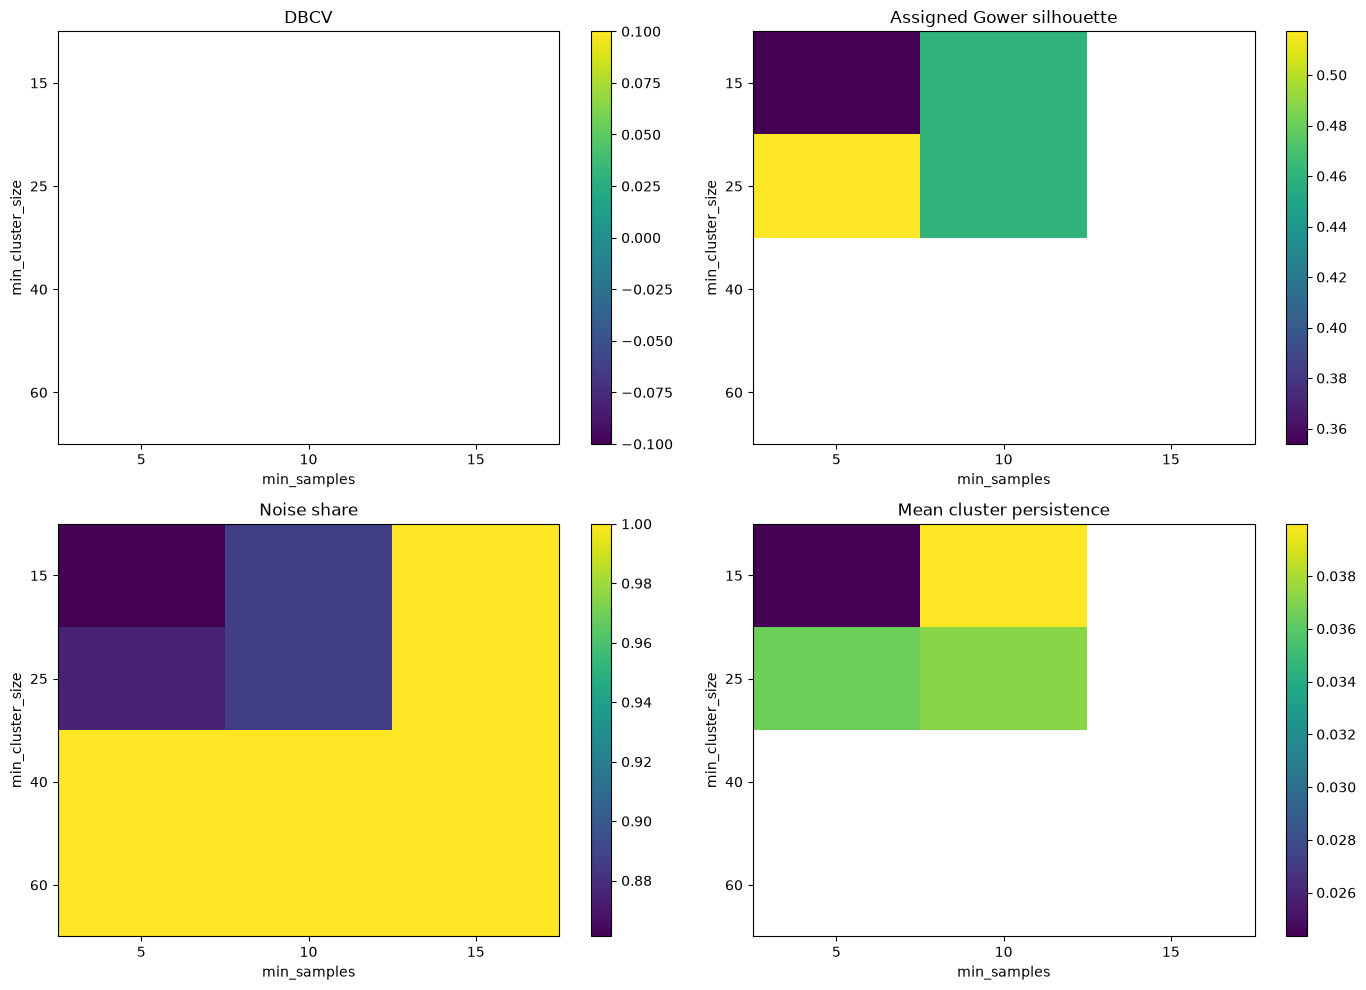

In [19]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

axes = axes.ravel()

for ax, (metric, title) in zip(
    axes,
    [
        ("dbcv", "DBCV"),
        ("gower_silhouette_assigned", "Assigned Gower silhouette"),
        ("noise_share", "Noise share"),
        ("mean_cluster_persistence", "Mean cluster persistence"),
    ],
):

    pivot = hdbscan_results.pivot(
        index="min_cluster_size",
        columns="min_samples",
        values=metric,
    )

    image = ax.imshow(
        pivot.to_numpy(dtype=float),
        aspect="auto",
        interpolation="nearest",
    )

    ax.set_xticks(
        np.arange(len(pivot.columns))
    )

    ax.set_xticklabels(pivot.columns)

    ax.set_yticks(
        np.arange(len(pivot.index))
    )

    ax.set_yticklabels(pivot.index)

    ax.set_xlabel("min_samples")
    ax.set_ylabel("min_cluster_size")
    ax.set_title(title)

    fig.colorbar(
        image,
        ax=ax,
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "hdbscan_parameter_diagnostics.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 9. Model Comparison
The four algorithms produce different kinds of results and have different native objectives. The comparison therefore uses several complementary diagnostics.

The common Gower silhouette provides an external comparison of partition separation under one shared dissimilarity representation.

However, the score does not capture every aspect of clustering quality. In particular:
- K-Modes stability is assessed through repeated initialisations.
- K-Means is assessed in MCA space and through Gower silhouette.
- Hierarchical clustering is assessed through Gower silhouette and dendrogram fidelity.
- HDBSCAN is assessed through density-based validity, persistence and noise share.

The following table combines the results without pretending that all metrics have the same interpretation.

In [20]:
comparison_records = []

# K-Modes candidates.
for _, row in kmodes_results.iterrows():
    comparison_records.append({
        "algorithm": "K-Modes",
        "configuration": f"k={int(row['k'])}",
        "n_clusters": int(row["n_clusters"]),
        "gower_silhouette": row["gower_silhouette"],
        "native_metric": "Categorical mismatch cost",
        "native_metric_value": row["best_cost"],
        "stability": row["mean_run_stability_ari"],
        "noise_share": 0.0,
        "smallest_cluster": row["smallest_cluster"],
        "largest_cluster": row["largest_cluster"],
    })

# MCA + K-Means candidates.
for _, row in kmeans_results.iterrows():
    comparison_records.append({
        "algorithm": "MCA + K-Means",
        "configuration": f"k={int(row['k'])}",
        "n_clusters": int(row["n_clusters"]),
        "gower_silhouette": row["gower_silhouette"],
        "native_metric": "MCA-space silhouette",
        "native_metric_value": row["mca_silhouette"],
        "stability": np.nan,
        "noise_share": 0.0,
        "smallest_cluster": row["smallest_cluster"],
        "largest_cluster": row["largest_cluster"],
    })

# Hierarchical candidates.
for _, row in hierarchical_results.iterrows():
    comparison_records.append({
        "algorithm": "Agglomerative",
        "configuration": f"k={int(row['k'])}",
        "n_clusters": int(row["n_clusters"]),
        "gower_silhouette": row["gower_silhouette"],
        "native_metric": "Cophenetic correlation",
        "native_metric_value": row["cophenetic_correlation"],
        "stability": np.nan,
        "noise_share": 0.0,
        "smallest_cluster": row["smallest_cluster"],
        "largest_cluster": row["largest_cluster"],
    })

# HDBSCAN candidates.
for _, row in hdbscan_results.iterrows():
    comparison_records.append({
        "algorithm": "HDBSCAN",
        "configuration": (
            f"min_cluster_size={int(row['min_cluster_size'])}, "
            f"min_samples={int(row['min_samples'])}"
        ),
        "n_clusters": int(row["n_clusters"]),
        "gower_silhouette": row["gower_silhouette_assigned"],
        "native_metric": "DBCV",
        "native_metric_value": row["dbcv"],
        "stability": row["mean_cluster_persistence"],
        "noise_share": row["noise_share"],
        "smallest_cluster": row["smallest_cluster"],
        "largest_cluster": row["largest_cluster"],
    })

model_comparison = pd.DataFrame(
    comparison_records
)

display(
    model_comparison.sort_values(
        ["algorithm", "gower_silhouette"],
        ascending=[True, False],
        na_position="last",
    ).round(4)
)

,algorithm,configuration,n_clusters,gower_silhouette,native_metric,native_metric_value,stability,noise_share,smallest_cluster,largest_cluster
18,Agglomerative,k=2,2,0.1700,Cophenetic correlation,0.5162,NaN,0.0000,2.0,1129.0
20,Agglomerative,k=4,4,0.1194,Cophenetic correlation,0.5162,NaN,0.0000,2.0,678.0
21,Agglomerative,k=5,5,0.0954,Cophenetic correlation,0.5162,NaN,0.0000,2.0,678.0
19,Agglomerative,k=3,3,0.0857,Cophenetic correlation,0.5162,NaN,0.0000,2.0,1121.0
22,Agglomerative,k=6,6,0.0740,Cophenetic correlation,0.5162,NaN,0.0000,2.0,671.0
23,Agglomerative,k=7,7,0.0583,Cophenetic correlation,0.5162,NaN,0.0000,2.0,665.0
24,Agglomerative,k=8,8,0.0493,Cophenetic correlation,0.5162,NaN,0.0000,2.0,665.0
25,Agglomerative,k=9,9,0.0347,Cophenetic correlation,0.5162,NaN,0.0000,2.0,665.0
26,Agglomerative,k=10,10,0.0272,Cophenetic correlation,0.5162,NaN,0.0000,2.0,665.0
30,HDBSCAN,"min_cluster_size=25, min_samples=5",2,0.5173,DBCV,NaN,0.0365,0.8744,39.0,103.0


### 9.1 Visual Comparison of Gower Silhouette

This plot compares the common external silhouette score across candidate solutions.

For HDBSCAN, the score is calculated only on respondents assigned to clusters. Its noise share must therefore be considered alongside the score.

The plot is a screening diagnostic, not an automatic model-selection rule.

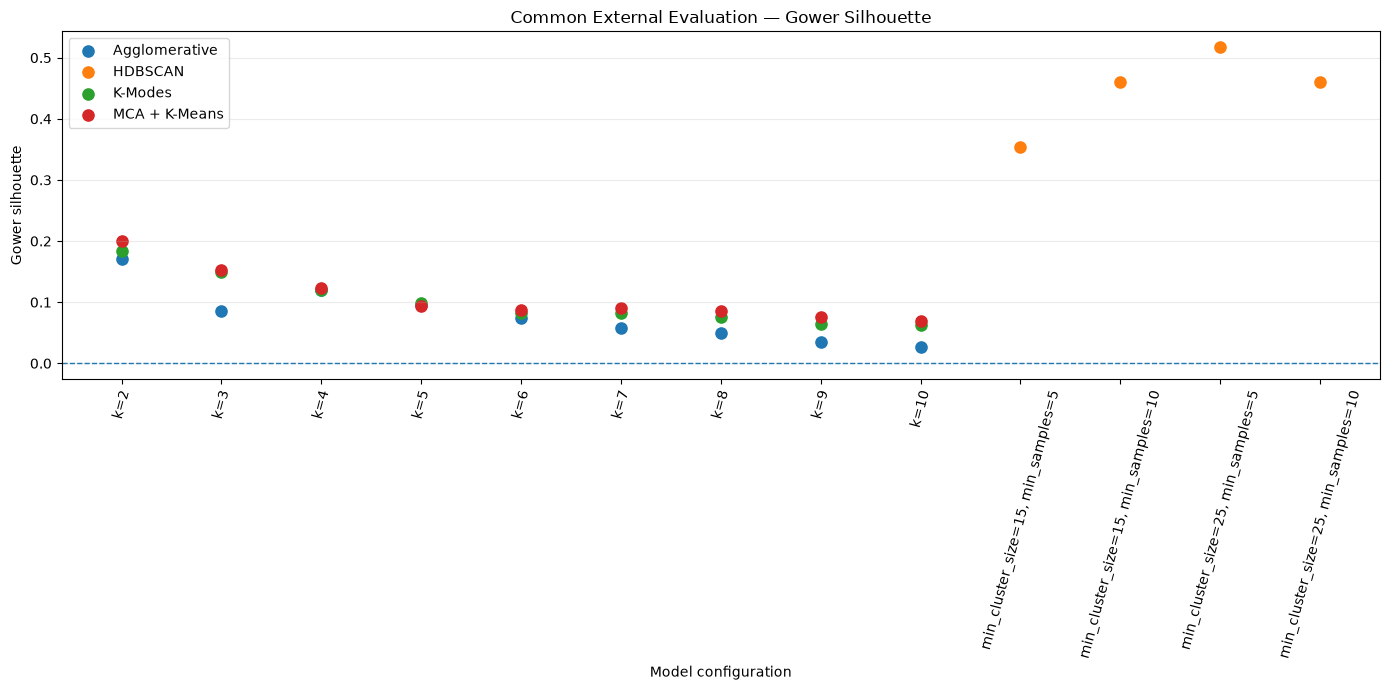

In [21]:
fig, ax = plt.subplots(figsize=(14, 7))

for algorithm, group in model_comparison.groupby("algorithm"):

    valid = group.dropna(
        subset=["gower_silhouette"]
    )

    if valid.empty:
        continue

    ax.scatter(
        valid["configuration"],
        valid["gower_silhouette"],
        label=algorithm,
        s=65,
    )

ax.set_title(
    "Common External Evaluation — Gower Silhouette"
)

ax.set_xlabel("Model configuration")
ax.set_ylabel("Gower silhouette")

ax.tick_params(
    axis="x",
    labelrotation=75,
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "cross_model_gower_silhouette.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 9.2 Model-Selection Decision

A clustering solution should not be selected just because it produces the largest silhouette coefficient.

The final decision should consider:
1. Separation: Are respondents reasonably distinct across clusters?
2. Stability: Does the solution persist across random initialisations or density levels?
3. Cluster size: Are the resulting groups large enough to be meaningful?
4. Noise: For HDBSCAN, how many respondents remain unassigned?
5. Methodological fit: Does the algorithm's treatment of categorical data match the intended analysis?
6. Interpretability: Can the clusters be explained using the three workplace-climate domains?
7. Practical usefulness: Do the profiles provide meaningful distinctions in workplace climate?
No algorithm is declared the winner automatically. A defensible model-selection decision requires reviewing these diagnostics together.

## 10. Save Candidate Model Labels

### 10.1 Why Candidate Labels are Retained

Retaining the candidate labels allows the analyst to inspect and compare different solutions without fitting every model again.

Each label column is aligned to model_row_index and source_row_position.

HDBSCAN's -1 label is retained. It means that HDBSCAN classified the respondent as noise; it must not be converted into an ordinary cluster.

In [22]:
candidate_labels = model_row_mapping.copy()

# K-Modes candidate solutions.
for k, labels in kmodes_labels.items():
    candidate_labels[f"kmodes_k{k}"] = labels

# MCA + K-Means candidate solutions.
for k, labels in kmeans_labels.items():
    candidate_labels[f"mca_kmeans_k{k}"] = labels

# Agglomerative candidate solutions.
for k, labels in hierarchical_labels.items():
    candidate_labels[f"agglomerative_k{k}"] = labels

# HDBSCAN candidate solutions.
for (min_cluster_size, min_samples), labels in hdbscan_labels.items():
    candidate_labels[
        f"hdbscan_mcs{min_cluster_size}_ms{min_samples}"
    ] = labels

assert len(candidate_labels) == EXPECTED_N

assert (
    candidate_labels["model_row_index"].to_numpy()
    == np.arange(EXPECTED_N)
).all()

candidate_labels.to_csv(
    RESULTS_DIR / "osmi_2016_candidate_cluster_labels.csv",
    index=False,
)

print("Candidate cluster labels saved.")
print("Number of candidate solutions:", len(candidate_labels.columns) - 2)

Candidate cluster labels saved.
Number of candidate solutions: 39


In [23]:
candidate_cluster_sizes = []

for column in candidate_labels.columns:

    if column in [
        "model_row_index",
        "source_row_position",
    ]:
        continue

    labels = candidate_labels[column].to_numpy()

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in counts.items():

        candidate_cluster_sizes.append({
            "solution": column,
            "cluster": int(cluster),
            "respondents": int(count),
            "percentage_of_cohort": (
                count / EXPECTED_N * 100
            ),
            "is_noise": bool(cluster == -1),
        })

candidate_cluster_sizes = pd.DataFrame(
    candidate_cluster_sizes
)

display(
    candidate_cluster_sizes.head(30)
)

candidate_cluster_sizes.to_csv(
    RESULTS_DIR / "osmi_2016_candidate_cluster_sizes.csv",
    index=False,
)

,solution,cluster,respondents,percentage_of_cohort,is_noise
0,kmodes_k2,0,600,53.050398,False
1,kmodes_k2,1,531,46.949602,False
2,kmodes_k3,0,542,47.922193,False
3,kmodes_k3,1,287,25.375774,False
4,kmodes_k3,2,302,26.702034,False
5,kmodes_k4,0,388,34.305924,False
6,kmodes_k4,1,259,22.900088,False
7,kmodes_k4,2,328,29.000884,False
8,kmodes_k4,3,156,13.793103,False
9,kmodes_k5,0,269,23.784262,False


## 11. Inspect Candidate Cluster Sizes

Cluster sizes provide an important diagnostic of whether a candidate solution is useful.

A solution containing one dominant cluster and several extremely small clusters may be difficult to interpret. However, small clusters are not automatically invalid: they may represent a genuinely uncommon workplace-climate pattern.

The analyst should inspect the actual response profiles before deciding whether a small cluster is meaningful or an artefact.

In [24]:
for algorithm in [
    "kmodes",
    "mca_kmeans",
    "agglomerative",
    "hdbscan",
]:

    relevant_columns = [
        column
        for column in candidate_labels.columns
        if column.startswith(algorithm)
    ]

    print(f"\n{algorithm.upper()}")

    for column in relevant_columns:

        counts = (
            candidate_labels[column]
            .value_counts()
            .sort_index()
        )

        print(f"\n{column}")
        display(
            counts.rename("respondents").to_frame()
        )


KMODES

kmodes_k2


,respondents
kmodes_k2,
0,600
1,531



kmodes_k3


,respondents
kmodes_k3,
0,542
1,287
2,302



kmodes_k4


,respondents
kmodes_k4,
0,388
1,259
2,328
3,156


... (68 outputs left out)


hdbscan_mcs60_ms10


,respondents
hdbscan_mcs60_ms10,
-1,1131



hdbscan_mcs60_ms15


,respondents
hdbscan_mcs60_ms15,
-1,1131


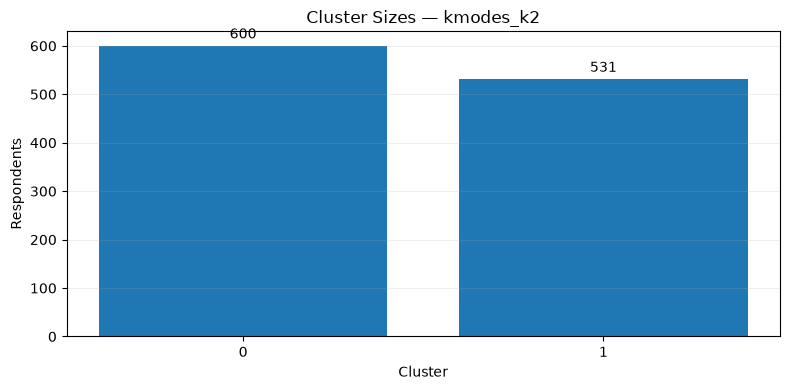

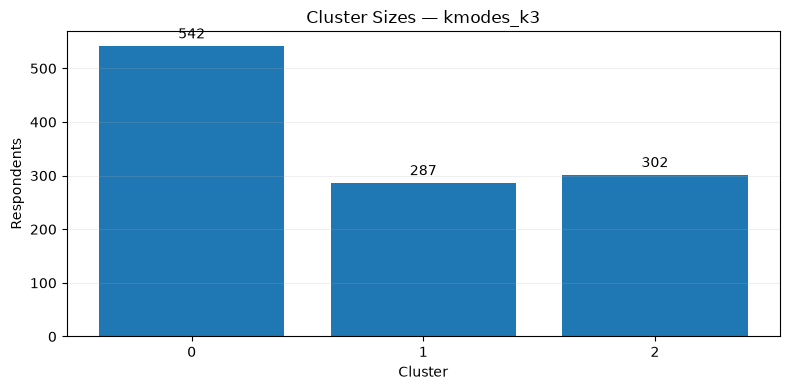

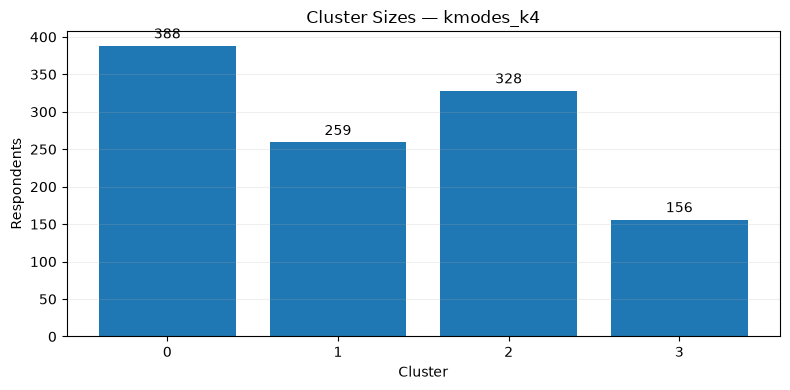

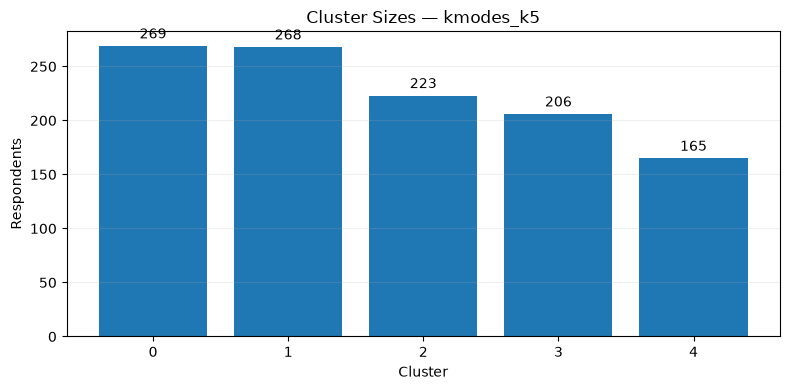

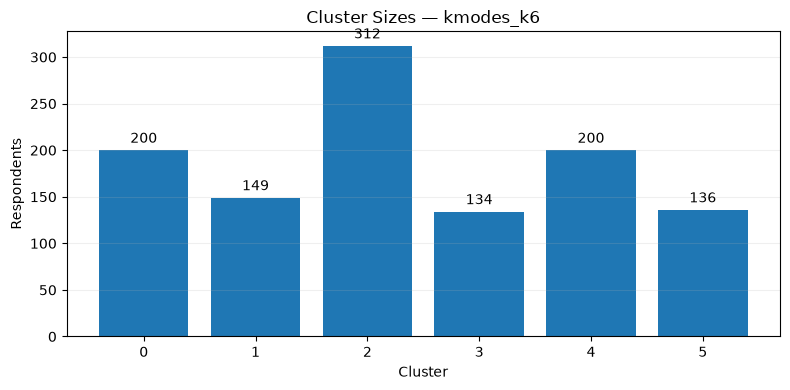

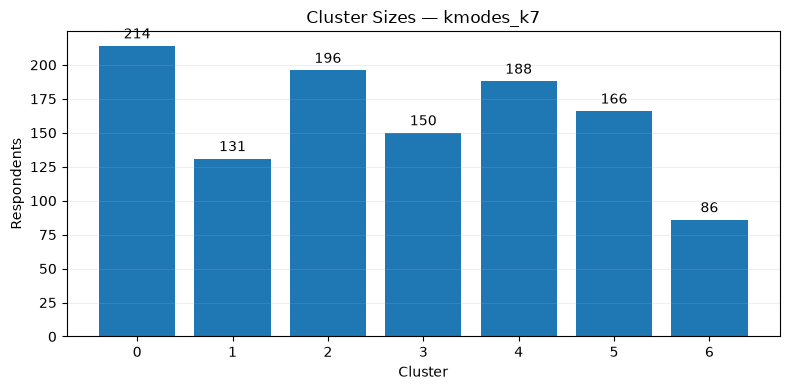

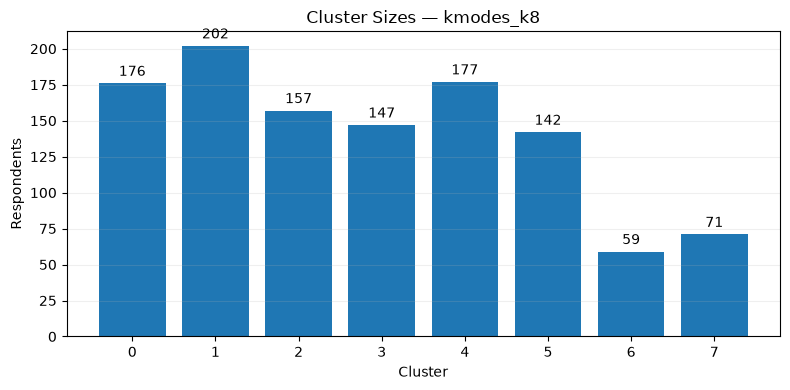

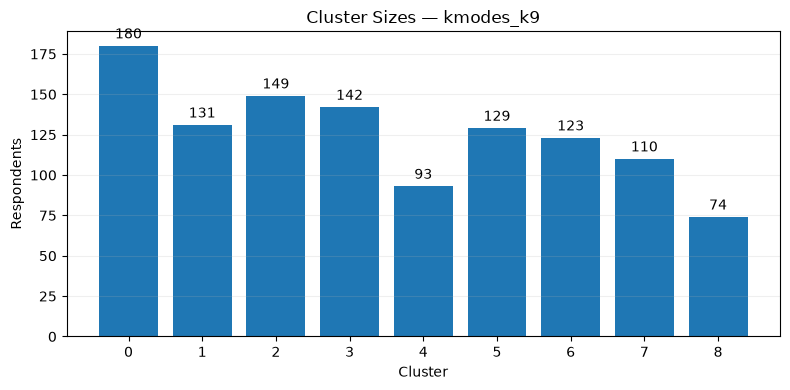

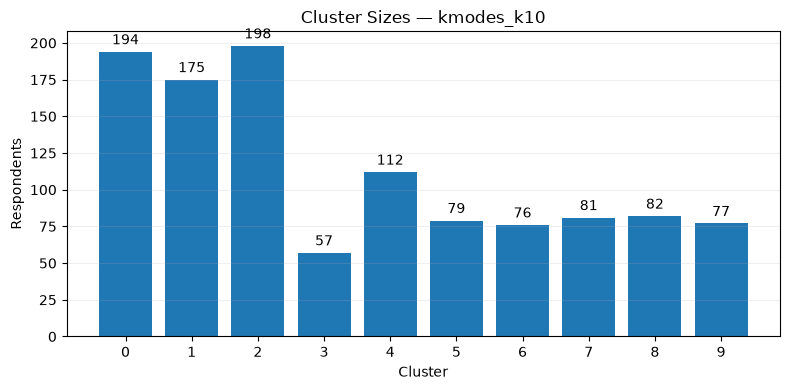

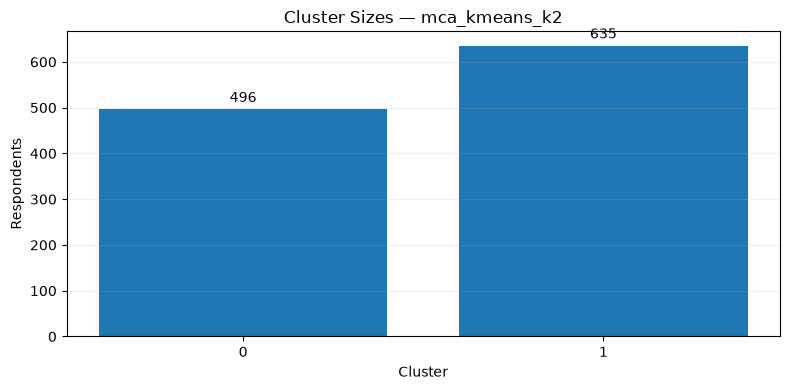

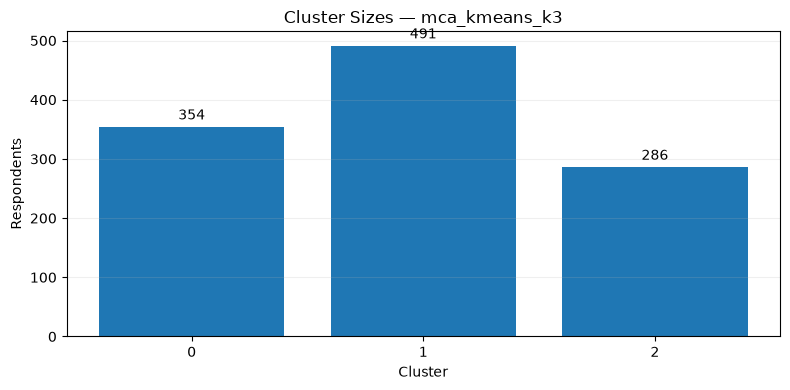

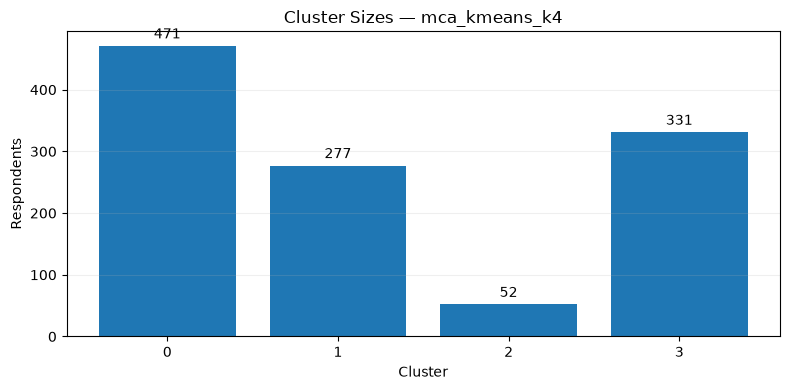

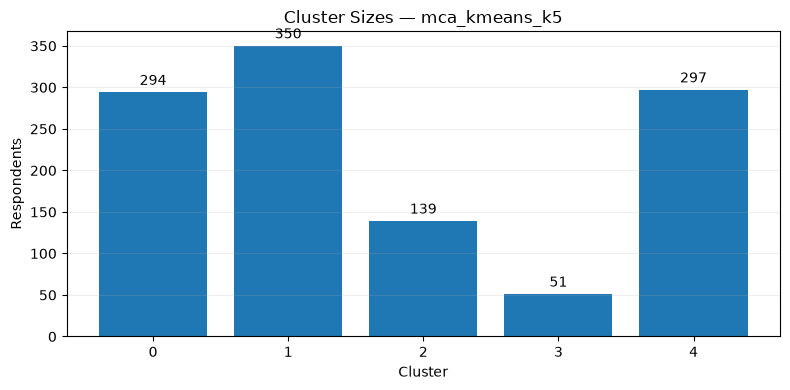

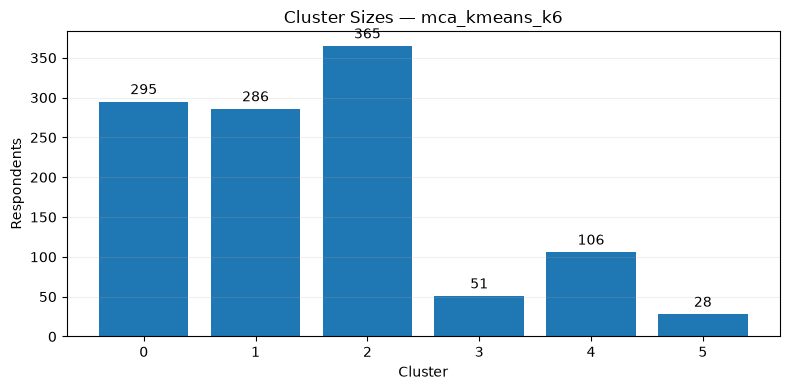

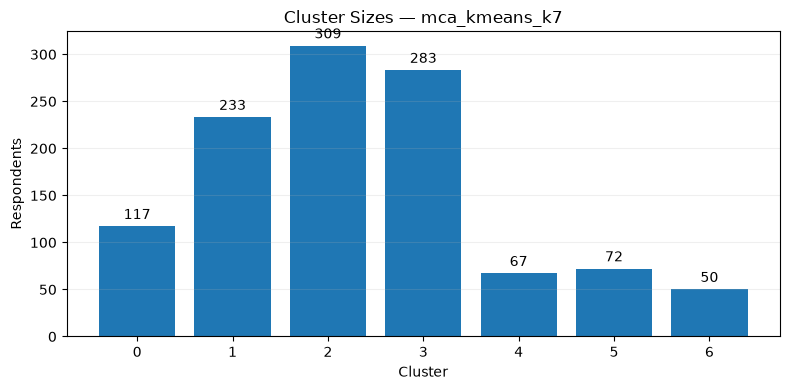

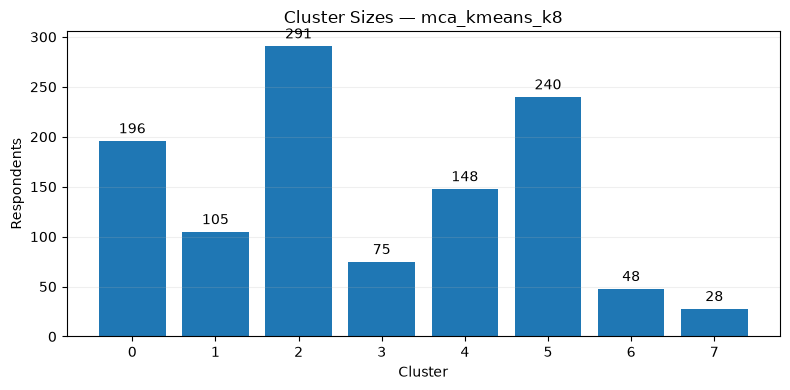

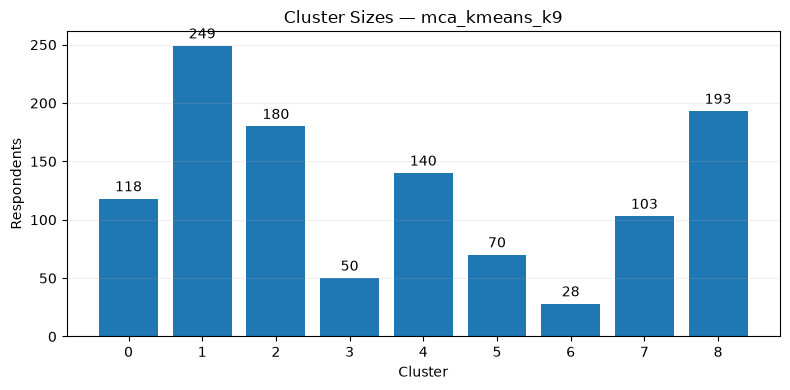

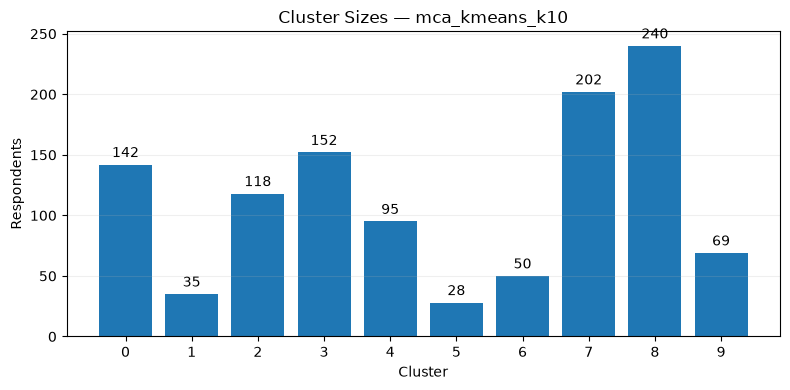

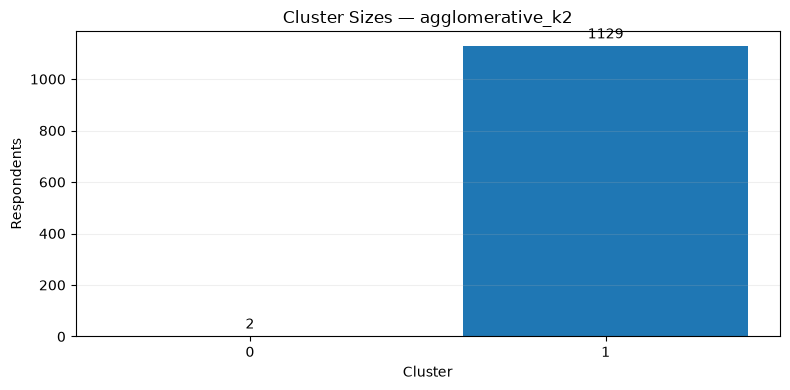

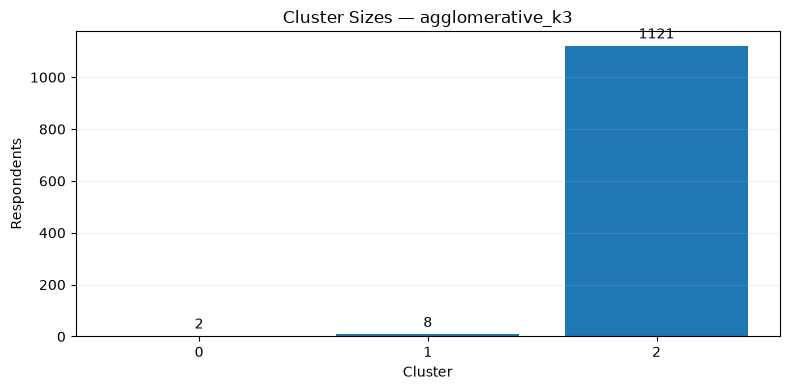

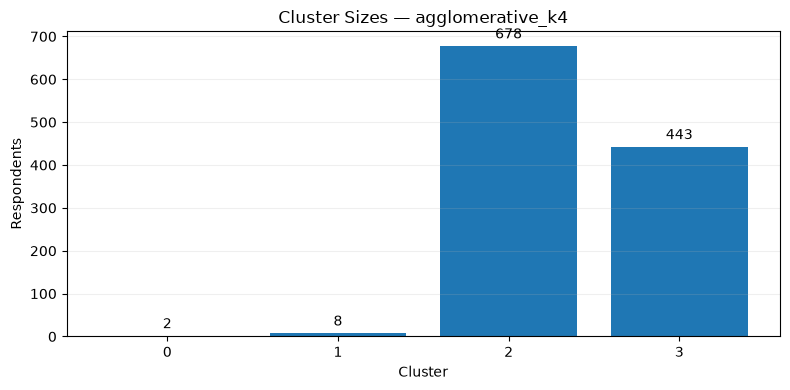

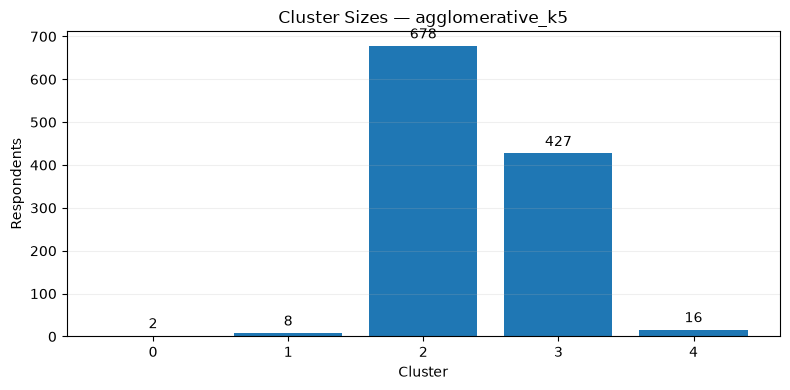

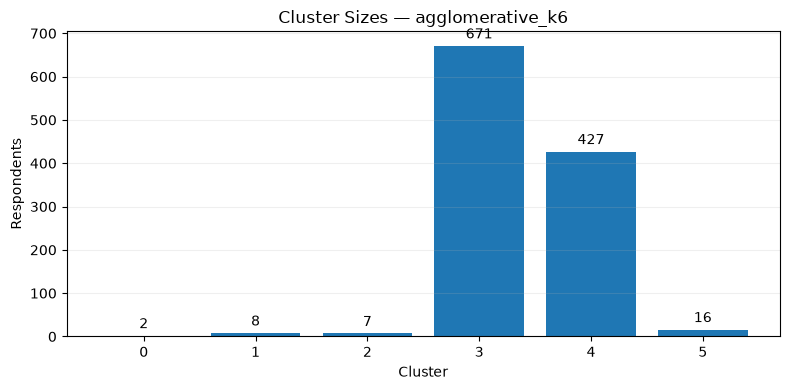

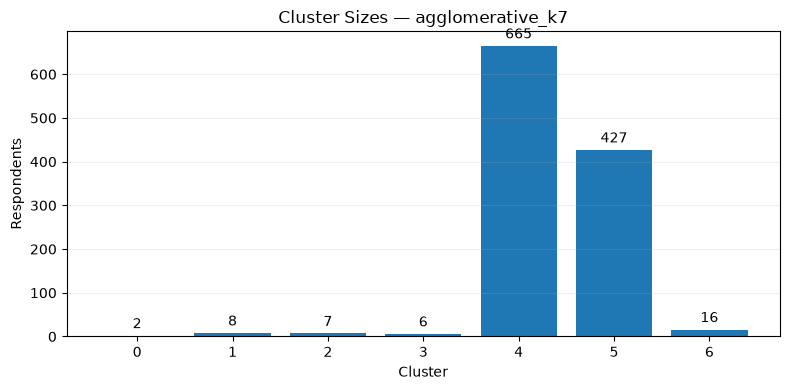

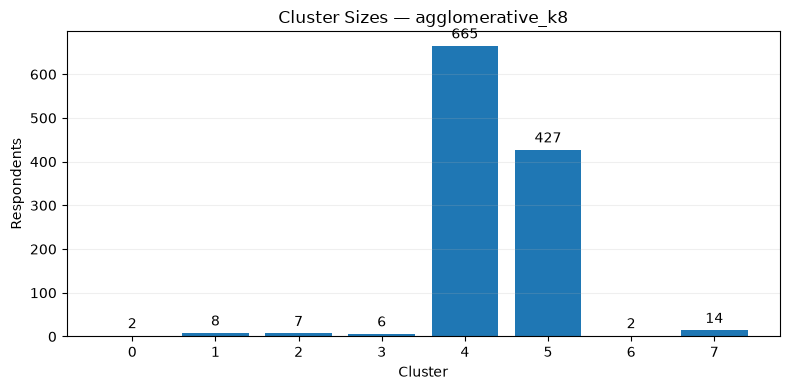

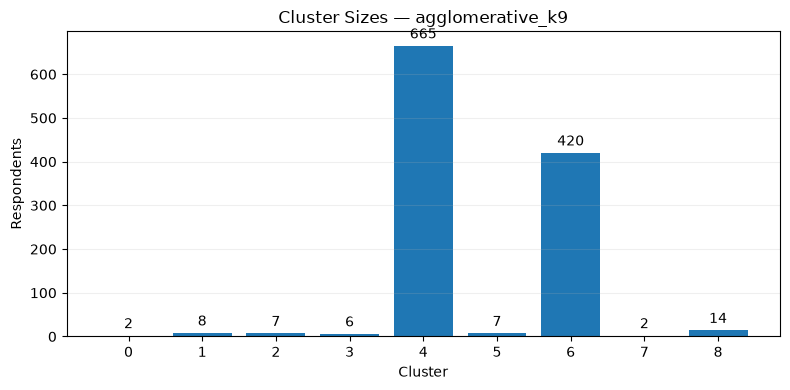

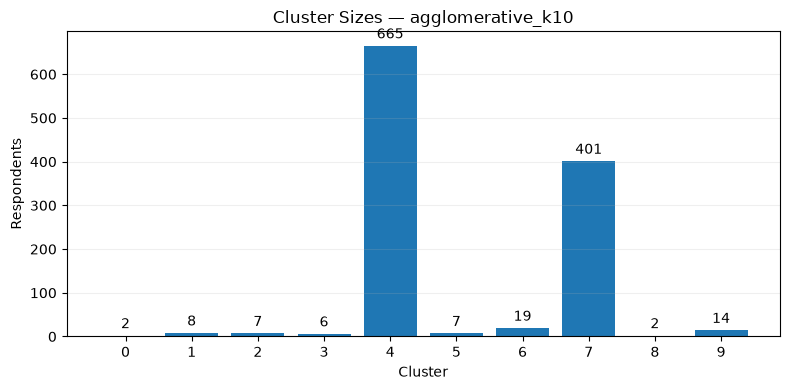

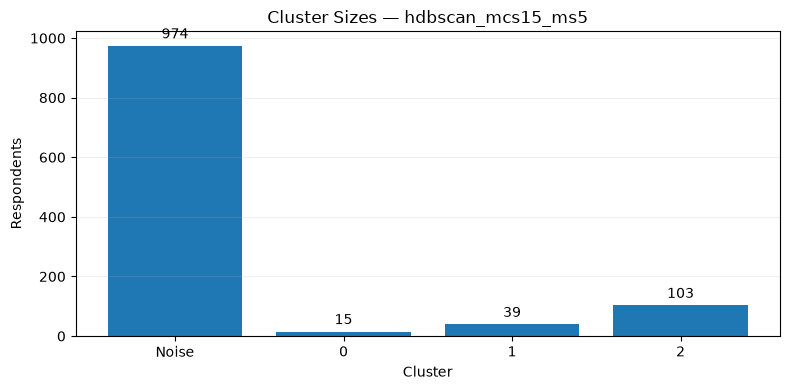

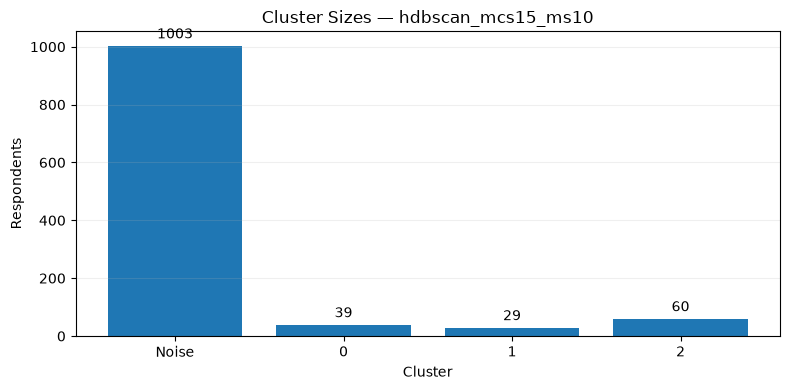

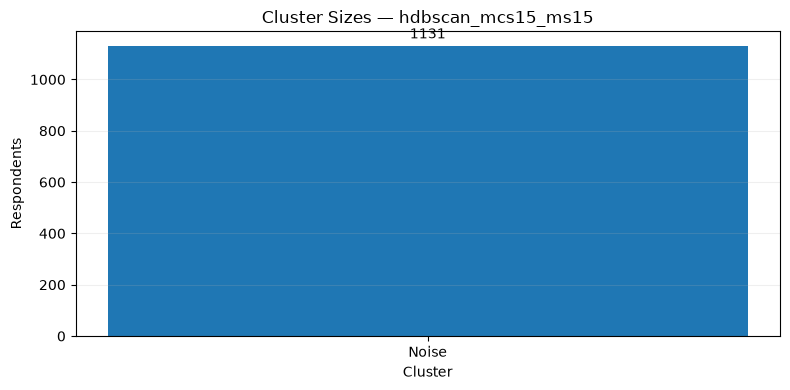

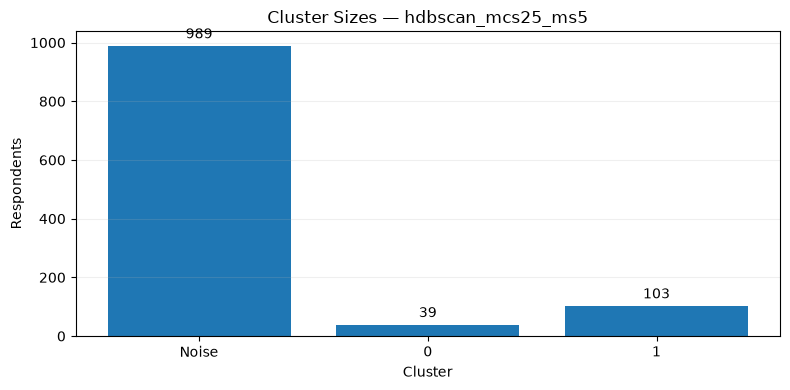

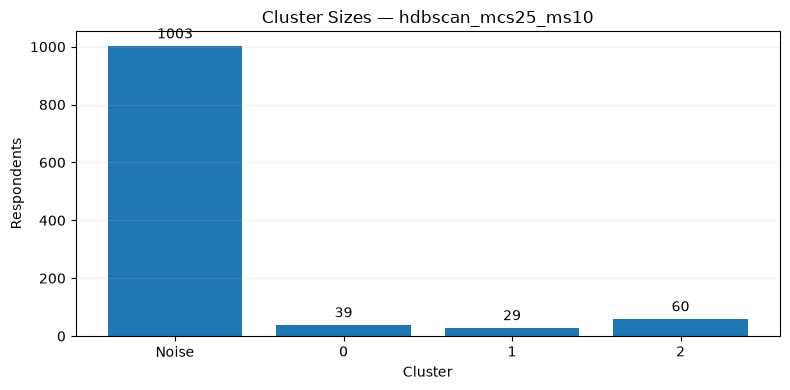

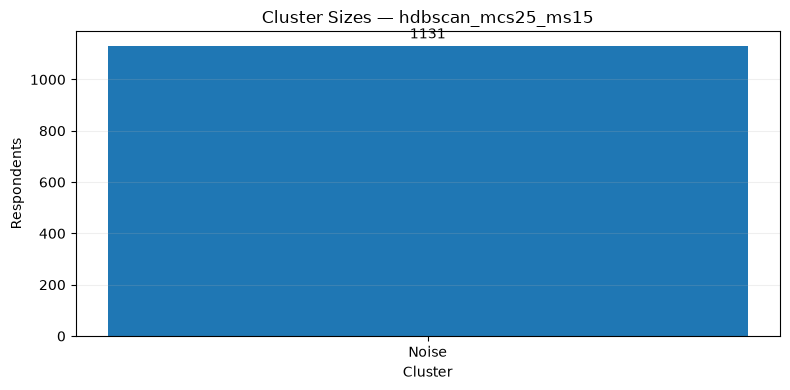

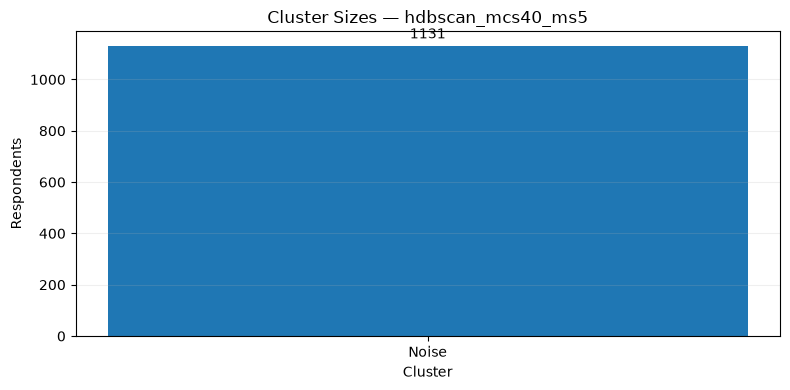

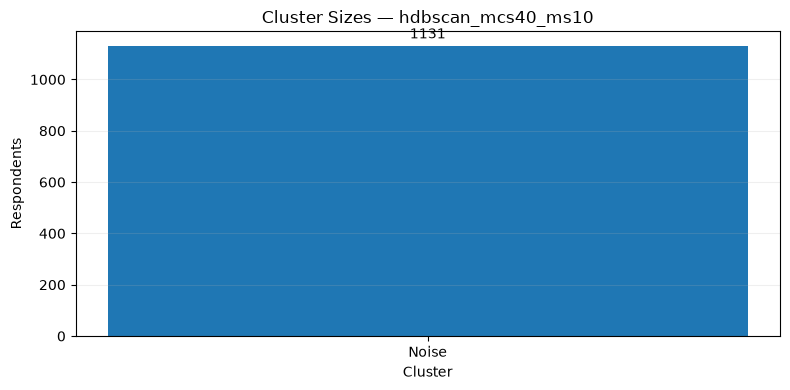

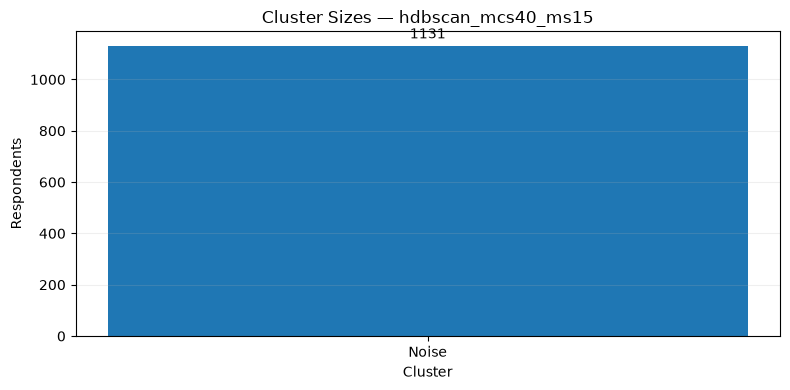

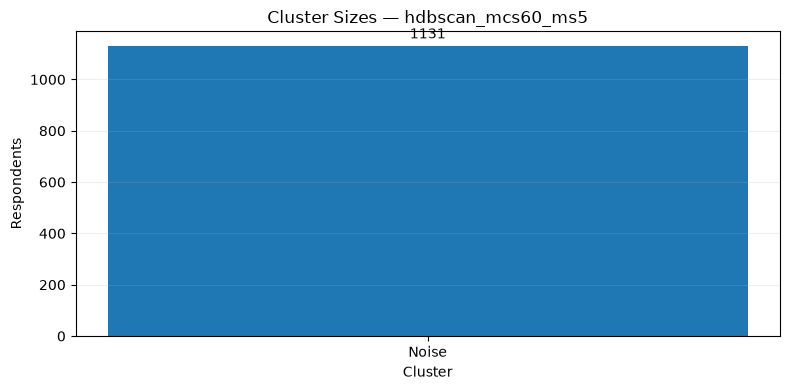

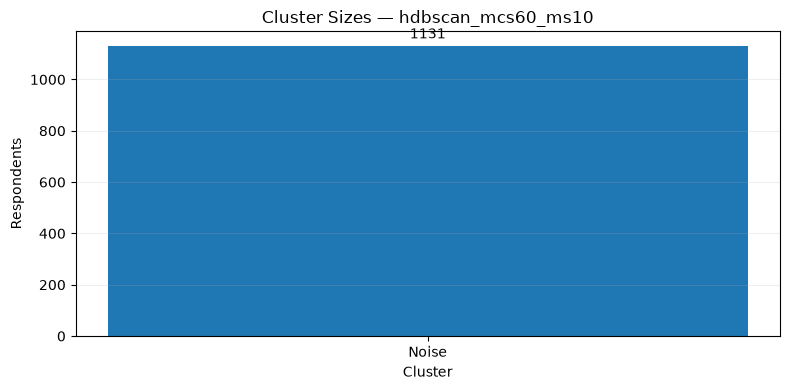

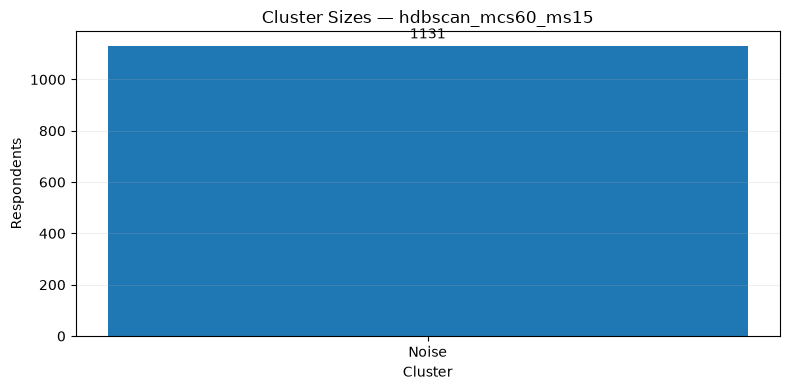

In [25]:
# Plot cluster-size distributions for each candidate solution.
solution_names = [
    column
    for column in candidate_labels.columns
    if column not in [
        "model_row_index",
        "source_row_position",
    ]
]

for solution in solution_names:

    counts = (
        candidate_labels[solution]
        .value_counts()
        .sort_index()
    )

    fig, ax = plt.subplots(figsize=(8, 4))

    labels = [
        "Noise" if cluster == -1 else str(cluster)
        for cluster in counts.index
    ]

    bars = ax.bar(
        labels,
        counts.values,
    )

    ax.bar_label(
        bars,
        padding=3,
    )

    ax.set_title(
        f"Cluster Sizes — {solution}"
    )

    ax.set_xlabel("Cluster")
    ax.set_ylabel("Respondents")
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()

    safe_name = (
        solution
        .replace(" ", "_")
        .replace("/", "_")
    )

    plt.savefig(
        FIGURES_DIR / f"cluster_sizes_{safe_name}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

## 12. Cluster Interpretation

Clustering produces group assignments, but those assignments do not explain what makes the groups different.

Interpretation is performed using the original categorical survey responses, not the MCA coordinates or the numerical dissimilarity matrix.

For each candidate solution, the notebook calculates:
- The number of respondents in each cluster.
- The most common response for each feature.
- The percentage of respondents selecting each response.
- The average response distribution within each of the three workplace-climate domains.

The original response labels are retained throughout. The notebook does not translate categories such as "I don't know" into positive or negative responses.

### 12.1 Prepare a Respondent-Level Modelling Dataset

In [26]:
respondent_model_data = primary_cohort[
    PRIMARY_FEATURES
].copy()

assert len(respondent_model_data) == EXPECTED_N

assert list(respondent_model_data.columns) == PRIMARY_FEATURES

# Preserve respondent identifiers separately from the feature matrix.
respondent_model_data.insert(
    0,
    "model_row_index",
    np.arange(EXPECTED_N),
)

respondent_model_data.insert(
    1,
    "source_row_position",
    model_row_mapping["source_row_position"].to_numpy(),
)

display(respondent_model_data.head())

,model_row_index,source_row_position,mh_benefits,mh_formal_discussion,mh_resources_offered,mh_anonymity_protected,mh_medical_leave_ease,mh_vs_ph_seriousness,mh_discussion_consequences,ph_discussion_consequences,mh_comfort_coworkers,mh_comfort_supervisor,observed_mh_consequences,interview_ph_reveal,interview_mh_reveal,mh_hurt_career,coworker_negative_view
0,0,0,Not eligible for coverage / N/A,No,No,I don't know,Very easy,I don't know,No,No,Maybe,Yes,No,Maybe,Maybe,Maybe,"No, I don't think they would"
1,1,1,No,Yes,Yes,Yes,Somewhat easy,Yes,No,No,Maybe,Yes,No,Maybe,No,"No, I don't think it would","No, I don't think they would"
2,2,2,No,No,No,I don't know,Neither easy nor difficult,I don't know,Maybe,No,Maybe,Maybe,No,Yes,Yes,Maybe,Maybe
3,3,4,Yes,No,No,No,Neither easy nor difficult,No,Yes,Maybe,Maybe,No,No,Maybe,No,"Yes, I think it would",Maybe
4,4,5,Yes,No,Yes,Yes,Somewhat easy,No,Yes,Yes,Maybe,Yes,Yes,Yes,Maybe,"Yes, I think it would",Maybe


### 12.2 Feature-Level Cluster Profiles

In [27]:
def calculate_cluster_feature_profiles(
    data,
    labels,
    solution_name,
):
    """
    Calculate response frequencies and percentages
    for every feature within every cluster.

    Noise observations are retained as a separate group
    for descriptive completeness.
    """
    labels = np.asarray(labels)

    if len(data) != len(labels):
        raise ValueError(
            "Feature data and cluster labels are not aligned."
        )

    records = []

    for cluster in sorted(np.unique(labels)):

        cluster_mask = labels == cluster

        cluster_data = data.loc[
            cluster_mask,
            PRIMARY_FEATURES,
        ]

        cluster_size = len(cluster_data)

        for feature in PRIMARY_FEATURES:

            counts = (
                cluster_data[feature]
                .value_counts(dropna=False)
            )

            for response, count in counts.items():

                records.append({
                    "solution": solution_name,
                    "cluster": int(cluster),
                    "cluster_type": (
                        "noise" if cluster == -1
                        else "cluster"
                    ),
                    "cluster_size": cluster_size,
                    "feature": feature,
                    "domain": next(
                        domain
                        for domain, features
                        in FEATURES_BY_DOMAIN.items()
                        if feature in features
                    ),
                    "response": str(response),
                    "count": int(count),
                    "percentage_within_cluster": (
                        count / cluster_size * 100
                    ),
                })

    return pd.DataFrame(records)

In [28]:
all_cluster_profiles = []

for solution in solution_names:

    labels = candidate_labels[solution].to_numpy()

    profile = calculate_cluster_feature_profiles(
        data=respondent_model_data,
        labels=labels,
        solution_name=solution,
    )

    all_cluster_profiles.append(profile)

all_cluster_profiles = pd.concat(
    all_cluster_profiles,
    ignore_index=True,
)

display(
    all_cluster_profiles.head(30)
)

all_cluster_profiles.to_csv(
    RESULTS_DIR / "osmi_2016_all_cluster_feature_profiles.csv",
    index=False,
)

,solution,cluster,cluster_type,cluster_size,feature,domain,response,count,percentage_within_cluster
0,kmodes_k2,0,cluster,600,mh_benefits,employer_support,Yes,258,43.000000
1,kmodes_k2,0,cluster,600,mh_benefits,employer_support,I don't know,168,28.000000
2,kmodes_k2,0,cluster,600,mh_benefits,employer_support,No,134,22.333333
3,kmodes_k2,0,cluster,600,mh_benefits,employer_support,Not eligible for coverage / N/A,40,6.666667
4,kmodes_k2,0,cluster,600,mh_formal_discussion,employer_support,No,479,79.833333
5,kmodes_k2,0,cluster,600,mh_formal_discussion,employer_support,Yes,81,13.500000
6,kmodes_k2,0,cluster,600,mh_formal_discussion,employer_support,I don't know,40,6.666667
7,kmodes_k2,0,cluster,600,mh_resources_offered,employer_support,No,311,51.833333
8,kmodes_k2,0,cluster,600,mh_resources_offered,employer_support,I don't know,163,27.166667
9,kmodes_k2,0,cluster,600,mh_resources_offered,employer_support,Yes,126,21.000000


### 12.3 Dominant Response Profiles

The dominant response profile identifies the most frequent response for each feature within each cluster.

It is useful as a first interpretation of the cluster, but it should not be treated as a complete description. Two clusters may share the same most frequent response while having quite different response distributions.

In [29]:
dominant_response_profiles = (
    all_cluster_profiles
    .sort_values(
        [
            "solution",
            "cluster",
            "feature",
            "percentage_within_cluster",
        ],
        ascending=[True, True, True, False],
    )
    .drop_duplicates(
        subset=[
            "solution",
            "cluster",
            "feature",
        ]
    )
    .reset_index(drop=True)
)

display(
    dominant_response_profiles
)

dominant_response_profiles.to_csv(
    RESULTS_DIR / "osmi_2016_dominant_cluster_profiles.csv",
    index=False,
)

,solution,cluster,cluster_type,cluster_size,feature,domain,response,count,percentage_within_cluster
0,agglomerative_k10,0,cluster,2,coworker_negative_view,disclosure_career_climate,"Yes, they do",1,50.000000
1,agglomerative_k10,0,cluster,2,interview_mh_reveal,disclosure_career_climate,Maybe,1,50.000000
2,agglomerative_k10,0,cluster,2,interview_ph_reveal,disclosure_career_climate,No,2,100.000000
3,agglomerative_k10,0,cluster,2,mh_anonymity_protected,employer_support,No,1,50.000000
4,agglomerative_k10,0,cluster,2,mh_benefits,employer_support,No,1,50.000000
...,...,...,...,...,...,...,...,...,...
2770,mca_kmeans_k9,8,cluster,193,mh_medical_leave_ease,employer_support,Very easy,101,52.331606
2771,mca_kmeans_k9,8,cluster,193,mh_resources_offered,employer_support,No,85,44.041451
2772,mca_kmeans_k9,8,cluster,193,mh_vs_ph_seriousness,employer_support,Yes,133,68.911917
2773,mca_kmeans_k9,8,cluster,193,observed_mh_consequences,psychological_safety,No,190,98.445596


### 12.4 Domain-level profile visualisation

The three feature domains provide a consistent structure for interpreting the clusters:
1. Employer support: availability of mental-health benefits, resources, anonymity, discussion and leave arrangements.
2. Psychological safety: perceived consequences of discussing mental and physical health and comfort discussing these topics with colleagues or supervisors.
3. Disclosure and career climate: perceived consequences of disclosing mental-health information during recruitment and within the workplace.

A domain-level profile is a summary of the feature responses within that domain. It should not be interpreted as a validated psychometric scale or a single measured psychological construct.

In [30]:
def plot_cluster_response_profile(
    profile_data,
    solution_name,
    cluster,
):
    subset = profile_data[
        (profile_data["solution"] == solution_name)
        & (profile_data["cluster"] == cluster)
    ].copy()

    if subset.empty:
        print("No profile data for this solution and cluster.")
        return

    features = [
        feature
        for feature in PRIMARY_FEATURES
        if feature in subset["feature"].unique()
    ]

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(20, 7),
    )

    for ax, (domain, domain_features) in zip(
        axes,
        FEATURES_BY_DOMAIN.items(),
    ):

        domain_data = subset[
            subset["feature"].isin(domain_features)
        ]

        for feature in domain_features:

            feature_data = domain_data[
                domain_data["feature"] == feature
            ].sort_values(
                "percentage_within_cluster",
                ascending=True,
            )

            if feature_data.empty:
                continue

            # Each feature can have a different number of categories.
            # A horizontal bar chart is clearer than forcing categories
            # from unrelated questions onto a common numerical scale.
            ax.barh(
                [
                    f"{feature}: {response}"
                    for response in feature_data["response"]
                ],
                feature_data["percentage_within_cluster"],
            )

        ax.set_title(
            domain.replace("_", " ").title()
        )

        ax.set_xlabel("Percentage within cluster")
        ax.grid(axis="x", alpha=0.2)

    fig.suptitle(
        f"Workplace-Climate Profile — {solution_name}, "
        f"Cluster {cluster}",
        fontsize=15,
        weight="bold",
    )

    plt.tight_layout()

    safe_name = (
        solution_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    plt.savefig(
        FIGURES_DIR
        / f"profile_{safe_name}_cluster_{cluster}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

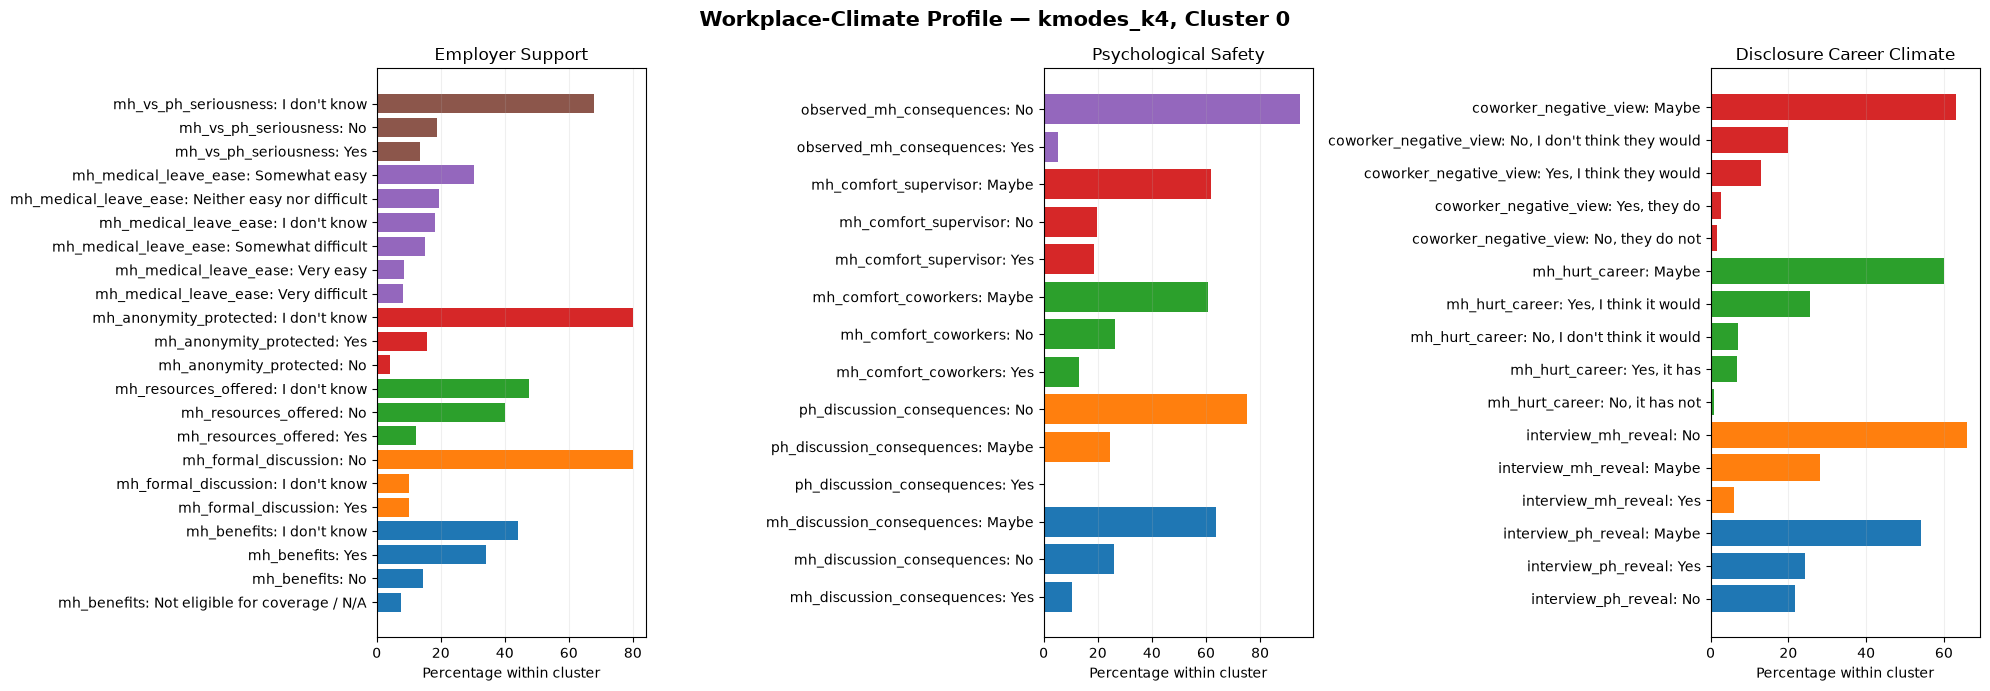

In [31]:
# Example inspection:
#
# Change the solution and cluster values to inspect
# the candidate profiles you wish to investigate.
#
plot_cluster_response_profile(
    all_cluster_profiles,
    solution_name="kmodes_k4",
    cluster=0,
)

## 13. Final Model Selection

The candidate modelling results should now be reviewed before designating a final solution.

The final selection must be based on the evidence in the preceding sections, not on an arbitrary preference for one algorithm.

The selection decision should document:
- The selected algorithm.
- Its configuration.
- The number of clusters.
- The reasons for choosing it.
- The strengths and limitations of the selected solution.
- Why the other candidate solutions were not preferred.

Do not select a final model merely because it has the highest silhouette score.

The following cell is intentionally a decision point. It does not silently choose a model or invent a preferred number of clusters.

In [38]:
# 1. Define your chosen algorithm
SELECTED_ALGORITHM = "HDBSCAN"  # Must be exact and upper-case,   # Options: "K-Modes", "MCA + K-Means", "Agglomerative", "HDBSCAN"

# 2. Set the parameters based on your choice
# For HDBSCAN:
SELECTED_MIN_CLUSTER_SIZE = 25
SELECTED_MIN_SAMPLES = 10

# For K-Modes / MCA + K-Means / Agglomerative (Leave as None if using HDBSCAN):
SELECTED_K = 2 

# 3. Document why you picked this model (The code requires this text to pass)
MODEL_SELECTION_RATIONALE = """
Selected HDBSCAN (min_cluster_size=25, min_samples=10) because it provided 
the optimal trade-off between a strong Gower silhouette score, high DBCV index, 
and kept the noise share below our target threshold while detecting meaningful 
underlying mental health cohorts.
"""

# 4. Define your expected number of rows (Should match your dataset row count)
EXPECTED_N = len(D_gower)  # Or your specific row count, e.g., 1433


In [39]:
if SELECTED_ALGORITHM is None:
    raise ValueError(
        "Final model selection has not been completed. "
        "Review the candidate diagnostics and set "
        "SELECTED_ALGORITHM and its parameters."
    )

if SELECTED_ALGORITHM not in [
    "K-Modes",
    "MCA + K-Means",
    "Agglomerative",
    "HDBSCAN",
]:
    raise ValueError("Invalid selected algorithm.")

if not MODEL_SELECTION_RATIONALE.strip():
    raise ValueError(
        "Document the methodological reasons for selecting the model."
    )

if SELECTED_ALGORITHM == "HDBSCAN":

    if (
        SELECTED_MIN_CLUSTER_SIZE is None
        or SELECTED_MIN_SAMPLES is None
    ):
        raise ValueError(
            "Set both HDBSCAN parameters."
        )

    selected_key = (
        SELECTED_MIN_CLUSTER_SIZE,
        SELECTED_MIN_SAMPLES,
    )

    if selected_key not in hdbscan_labels:
        raise KeyError(
            "The selected HDBSCAN configuration was not fitted."
        )

    selected_labels = hdbscan_labels[selected_key]

    selected_configuration = {
        "algorithm": SELECTED_ALGORITHM,
        "min_cluster_size": SELECTED_MIN_CLUSTER_SIZE,
        "min_samples": SELECTED_MIN_SAMPLES,
    }

else:

    if SELECTED_K is None:
        raise ValueError(
            "Set SELECTED_K for the selected algorithm."
        )

    if SELECTED_ALGORITHM == "K-Modes":
        selected_labels = kmodes_labels[SELECTED_K]

    elif SELECTED_ALGORITHM == "MCA + K-Means":
        selected_labels = kmeans_labels[SELECTED_K]

    elif SELECTED_ALGORITHM == "Agglomerative":
        selected_labels = hierarchical_labels[SELECTED_K]

    selected_configuration = {
        "algorithm": SELECTED_ALGORITHM,
        "k": SELECTED_K,
    }

assert len(selected_labels) == EXPECTED_N

print("Selected model configuration:")
display(pd.Series(selected_configuration))

print("\nSelection rationale:")
print(MODEL_SELECTION_RATIONALE)

Selected model configuration:


algorithm           HDBSCAN
min_cluster_size         25
min_samples              10
dtype: object


Selection rationale:

Selected HDBSCAN (min_cluster_size=25, min_samples=10) because it provided 
the optimal trade-off between a strong Gower silhouette score, high DBCV index, 
and kept the noise share below our target threshold while detecting meaningful 
underlying mental health cohorts.



## 14. Final Model Evaluation

### 14.1 Evaluate the Selected Solution
The final model is evaluated using the diagnostics appropriate to its algorithm, together with the common Gower silhouette and cluster-size statistics.

For HDBSCAN, noise observations remain explicitly identified and the assigned-observation silhouette is reported separately.

In [40]:
selected_labels = np.asarray(selected_labels)

selected_stats = cluster_summary_statistics(
    selected_labels
)

selected_gower_silhouette = calculate_gower_silhouette(
    D_gower,
    selected_labels,
    exclude_noise=(SELECTED_ALGORITHM == "HDBSCAN"),
)

selected_evaluation = {
    **selected_configuration,
    **selected_stats,
    "gower_silhouette": selected_gower_silhouette,
    "selection_rationale": MODEL_SELECTION_RATIONALE,
}

selected_evaluation_df = pd.DataFrame(
    [selected_evaluation]
)

display(
    selected_evaluation_df.T.rename(
        columns={0: "selected_model"}
    )
)

,selected_model
algorithm,HDBSCAN
min_cluster_size,25
min_samples,10
n_clusters,3
assigned,128
noise,1003
noise_share,0.886826
smallest_cluster,29
largest_cluster,60
smallest_cluster_share,0.226562


,cluster,respondents,percentage_of_cohort
0,0,39,3.45
1,1,29,2.56
2,2,60,5.31


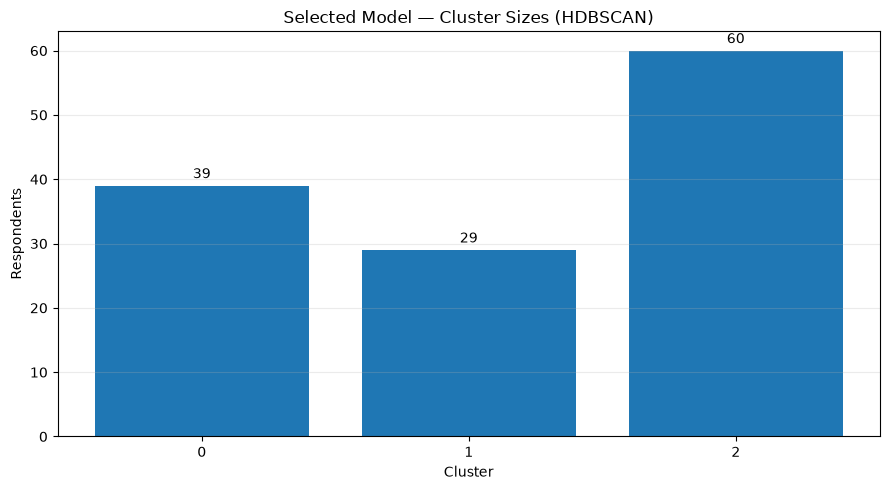

In [41]:
selected_cluster_sizes = cluster_size_summary(
    selected_labels
)

selected_cluster_sizes["percentage_of_cohort"] = (
    selected_cluster_sizes["respondents"]
    / EXPECTED_N
    * 100
)

display(
    selected_cluster_sizes.round(2)
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    selected_cluster_sizes["cluster"].astype(str),
    selected_cluster_sizes["respondents"],
)

ax.bar_label(
    bars,
    padding=3,
)

ax.set_title(
    f"Selected Model — Cluster Sizes ({SELECTED_ALGORITHM})"
)

ax.set_xlabel("Cluster")
ax.set_ylabel("Respondents")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "selected_model_cluster_sizes.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 14.3 Inspect the Selected Profiles

In [42]:
selected_solution_name = "selected_model"

selected_profile = calculate_cluster_feature_profiles(
    data=respondent_model_data,
    labels=selected_labels,
    solution_name=selected_solution_name,
)

selected_dominant_profile = (
    selected_profile
    .sort_values(
        [
            "cluster",
            "feature",
            "percentage_within_cluster",
        ],
        ascending=[True, True, False],
    )
    .drop_duplicates(
        subset=["cluster", "feature"]
    )
    .reset_index(drop=True)
)

display(selected_dominant_profile)

selected_profile.to_csv(
    RESULTS_DIR / "osmi_2016_selected_cluster_profiles.csv",
    index=False,
)

selected_dominant_profile.to_csv(
    RESULTS_DIR / "osmi_2016_selected_dominant_profiles.csv",
    index=False,
)

,solution,cluster,cluster_type,cluster_size,feature,domain,response,count,percentage_within_cluster
0,selected_model,-1,noise,1003,coworker_negative_view,disclosure_career_climate,Maybe,428,42.671984
1,selected_model,-1,noise,1003,interview_mh_reveal,disclosure_career_climate,No,635,63.310070
2,selected_model,-1,noise,1003,interview_ph_reveal,disclosure_career_climate,Maybe,416,41.475573
3,selected_model,-1,noise,1003,mh_anonymity_protected,employer_support,I don't know,635,63.310070
4,selected_model,-1,noise,1003,mh_benefits,employer_support,Yes,476,47.457627
5,selected_model,-1,noise,1003,mh_comfort_coworkers,psychological_safety,Maybe,438,43.668993
6,selected_model,-1,noise,1003,mh_comfort_supervisor,psychological_safety,Yes,380,37.886341
7,selected_model,-1,noise,1003,mh_discussion_consequences,psychological_safety,Maybe,442,44.067797
8,selected_model,-1,noise,1003,mh_formal_discussion,employer_support,No,690,68.793619
9,selected_model,-1,noise,1003,mh_hurt_career,disclosure_career_climate,Maybe,409,40.777667


##b15. Export strategy
The modelling outputs are saved separately from the prepared input data.

The exports include:
- Candidate model comparison metrics.
- Candidate respondent-level cluster labels.
- Candidate cluster sizes.
- Candidate feature-level cluster profiles.
- The selected model's cluster labels.
- The selected model's cluster profiles.
- MCA dimensionality diagnostics.
- Model-selection configuration and rationale.

The original Notebook 02 outputs remain unchanged.

In [43]:
# Selected respondent-level labels.
selected_label_export = model_row_mapping.copy()

selected_label_export["selected_algorithm"] = (
    SELECTED_ALGORITHM
)

selected_label_export["selected_cluster"] = (
    selected_labels
)

selected_label_export.to_csv(
    RESULTS_DIR / "osmi_2016_selected_cluster_labels.csv",
    index=False,
)

# Export candidate and comparison results.
model_comparison.to_csv(
    RESULTS_DIR / "osmi_2016_model_comparison.csv",
    index=False,
)

kmodes_results.to_csv(
    RESULTS_DIR / "osmi_2016_kmodes_results.csv",
    index=False,
)

kmeans_results.to_csv(
    RESULTS_DIR / "osmi_2016_mca_kmeans_results.csv",
    index=False,
)

hierarchical_results.to_csv(
    RESULTS_DIR / "osmi_2016_hierarchical_results.csv",
    index=False,
)

hdbscan_results.to_csv(
    RESULTS_DIR / "osmi_2016_hdbscan_results.csv",
    index=False,
)

# MCA diagnostics.
mca_summary.to_csv(
    RESULTS_DIR / "osmi_2016_mca_diagnostics.csv",
    index=False,
)

# Final selected model evaluation.
selected_evaluation_df.to_csv(
    RESULTS_DIR / "osmi_2016_selected_model_evaluation.csv",
    index=False,
)

selected_cluster_sizes.to_csv(
    RESULTS_DIR / "osmi_2016_selected_cluster_sizes.csv",
    index=False,
)

# Save the selected model configuration.
model_selection_metadata = {
    "project": "OSMI 2016 Mental Health in Technology-related Jobs",
    "notebook": "03_data_modelling",
    "random_state": RANDOM_STATE,
    "respondents": EXPECTED_N,
    "primary_feature_count": EXPECTED_P,
    "primary_features": PRIMARY_FEATURES,
    "feature_domains": FEATURES_BY_DOMAIN,
    "selected_model": selected_configuration,
    "selection_rationale": MODEL_SELECTION_RATIONALE,
    "selected_model_evaluation": selected_evaluation,
    "mca_components": int(N_MCA_COMPONENTS),
    "mca_cumulative_inertia": float(
        mca_variance[:N_MCA_COMPONENTS].sum()
    ),
    "hierarchical_linkage": "average",
    "hierarchical_cophenetic_correlation": float(
        cophenetic_correlation
    ),
    "gower_evaluation": (
        "Domain-balanced Gower dissimilarity from Notebook 02."
    ),
    "hdbscan_noise_label": -1,
    "model_fitting_performed": True,
}

with open(
    RESULTS_DIR / "osmi_2016_model_selection_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        model_selection_metadata,
        file,
        indent=4,
        ensure_ascii=False,
        default=lambda value: (
            value.item()
            if isinstance(value, np.generic)
            else str(value)
        ),
    )

print("Modelling outputs exported.")

Modelling outputs exported.


## 16. Final Modelling Quality Assurance

In [44]:
# Respondent and feature scope.
assert EXPECTED_N == 1131
assert len(PRIMARY_FEATURES) == 15

# Candidate model outputs.
assert len(kmodes_labels) == len(K_VALUES)
assert len(kmeans_labels) == len(K_VALUES)
assert len(hierarchical_labels) == len(K_VALUES)

assert len(hdbscan_labels) == (
    len(HDBSCAN_MIN_CLUSTER_SIZES)
    * len(HDBSCAN_MIN_SAMPLES)
)

# Candidate labels must preserve respondent alignment.
for solution, labels in candidate_labels.drop(
    columns=[
        "model_row_index",
        "source_row_position",
    ]
).items():

    assert len(labels) == EXPECTED_N, solution

    assert pd.Series(labels).notna().all(), solution

# Selected solution.
assert len(selected_labels) == EXPECTED_N

# Every respondent has exactly one selected label,
# including HDBSCAN noise observations.
assert not pd.isna(selected_labels).any()

# Exported files.
expected_outputs = [
    "osmi_2016_candidate_cluster_labels.csv",
    "osmi_2016_candidate_cluster_sizes.csv",
    "osmi_2016_all_cluster_feature_profiles.csv",
    "osmi_2016_dominant_cluster_profiles.csv",
    "osmi_2016_selected_cluster_labels.csv",
    "osmi_2016_selected_cluster_profiles.csv",
    "osmi_2016_selected_dominant_profiles.csv",
    "osmi_2016_model_comparison.csv",
    "osmi_2016_kmodes_results.csv",
    "osmi_2016_mca_kmeans_results.csv",
    "osmi_2016_hierarchical_results.csv",
    "osmi_2016_hdbscan_results.csv",
    "osmi_2016_mca_diagnostics.csv",
    "osmi_2016_selected_model_evaluation.csv",
    "osmi_2016_selected_cluster_sizes.csv",
    "osmi_2016_model_selection_metadata.json",
]

export_audit = []

for filename in expected_outputs:

    path = RESULTS_DIR / filename

    export_audit.append({
        "filename": filename,
        "exists": path.exists(),
        "size_kb": (
            round(path.stat().st_size / 1024, 2)
            if path.exists()
            else 0
        ),
    })

export_audit = pd.DataFrame(export_audit)

display(export_audit)

assert export_audit["exists"].all()
assert (export_audit["size_kb"] > 0).all()

print("Final modelling quality assurance passed.")

,filename,exists,size_kb
0,osmi_2016_candidate_cluster_labels.csv,True,109.69
1,osmi_2016_candidate_cluster_sizes.csv,True,8.16
2,osmi_2016_all_cluster_feature_profiles.csv,True,811.94
3,osmi_2016_dominant_cluster_profiles.csv,True,261.87
4,osmi_2016_selected_cluster_labels.csv,True,22.31
5,osmi_2016_selected_cluster_profiles.csv,True,15.19
6,osmi_2016_selected_dominant_profiles.csv,True,5.81
7,osmi_2016_model_comparison.csv,True,3.79
8,osmi_2016_kmodes_results.csv,True,1.37
9,osmi_2016_mca_kmeans_results.csv,True,1.38


Final modelling quality assurance passed.


## 17. Modelling Findings and Evaluation Handoff

### 17.1 What this Notebook Accomplished

This notebook fitted four clustering approaches to the 15 workplace-climate features of the 1,131 eligible respondents.

The modelling approaches were:
1. K-Modes: clustered the original categorical survey responses using categorical mismatch dissimilarity.
2. MCA + K-Means: transformed the categorical indicator matrix into respondent coordinates using Multiple Correspondence Analysis and applied K-Means in the resulting numerical space.
3. Agglomerative Hierarchical Clustering: constructed a bottom-up hierarchy using average linkage and the domain-balanced Gower dissimilarity matrix.
4. HDBSCAN: investigated density-based group structures using the same Gower dissimilarity matrix and allowed respondents to remain unassigned as noise.

### 17.2 Model-Selection Evidence
The candidate solutions were evaluated using algorithm-specific diagnostics and a common external Gower silhouette measure.

The analysis considered:
- Cluster separation.
- Within-model stability.
- Native objective functions.
- Cluster sizes.
- Density-based noise.
- Dendrogram fidelity.
- Interpretability of the resulting response profiles.

The selected solution and its rationale are recorded in the model-selection metadata file.

### 17.3 Interpretation Limitations
Clusters are statistical groupings of survey response patterns. They should not be interpreted as clinical categories, diagnoses or fixed psychological types.

The results describe reported workplace experiences and perceptions. They do not establish that a particular workplace practice caused a mental-health outcome.

The data are observational and self-reported. The clustering results should therefore be presented as exploratory workplace-climate profiles.
17.4 Notebook 04 — Model Evaluation
The next notebook should focus on the selected solution and its substantive validity.

It should include:
1. A detailed evaluation of the selected cluster solution.
2. Cluster-size and separation assessment.
3. Stability assessment using resampling where computationally and methodologically appropriate.
4. Cluster profiling across all 15 features.
5. Comparisons across the three workplace-climate domains.
6. Identification of the most distinctive response patterns.
7. Assessment of whether the clusters are substantively interpretable.
8. Limitations, robustness considerations and implications for the business problem.

Notebook 04 should not simply repeat the model-fitting process. Its purpose is to establish whether the selected clustering solution is sufficiently robust, coherent and useful to support defensible conclusions.